# PID tuning for lane-keeping (i.e., lateral) and cruise-contrl (i.e., longitudinal)

Activity map:

1. Edit only the six finite values in `pid-gains`.
2. Read the lane and cruise starter plots, then compare the staged P/D/I evidence.
3. Inspect the combined validation with all six selected gains.
4. Use the final evaluation to compare the selected controller under paired uncertainty.

Run smoke first to check mechanics; switch to full mode before substantive interpretation.

## AN IMPORTANT CAVEAT FOR THIS NOTEBOOK

* This notebook will likely feel messy and unclear to work through.
* In pervious years of the AI4R subject, tuning a PID policy was an important part of the Upskilling assignment.
* This year (i.e., 2026), tuning a PID policy is only an engagement token part of the Upskilling.
* Hence, try to move through this notebook without spending too much time tuning the PID gain.
* The bulk of your time for the Upskilling assignment should be spent synthesizing and tuning Rl and MPC policies.

## Colab Setup

* When running on **Colab**, this cell installs the pinned course package.
* When running **locally** on your computer, this cell does nothing.

In [74]:
from pathlib import Path
import importlib
import os
import site
import subprocess
import sys
import sysconfig

COURSE_REPOSITORY = "https://gitlab.unimelb.edu.au/dream/dream-gym.git"
COURSE_SOURCE_REF = "v0.2.2"
COLAB_CHECKOUT = Path("/content/dream-gym")
setup_diagnostic = None

try:
    import google.colab  # type: ignore[import-not-found]
except ImportError:
    IS_COLAB = False
else:
    IS_COLAB = True

if IS_COLAB:
    if "dreamgym" in sys.modules:
        setup_diagnostic = "restart the Colab runtime before continuing"
    else:
        try:
            if COLAB_CHECKOUT.exists():
                if not (COLAB_CHECKOUT / ".git").is_dir():
                    raise RuntimeError("existing checkout is not owned by git")
                origin = subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "remote", "get-url", "origin"),
                    capture_output=True, text=True, check=True,
                ).stdout.strip()
                if origin != COURSE_REPOSITORY:
                    raise RuntimeError("existing checkout has the wrong origin")
                dirty = subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "status", "--porcelain"),
                    capture_output=True, text=True, check=True,
                ).stdout.strip()
                if dirty:
                    raise RuntimeError("existing checkout is dirty")
                subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "fetch", "--depth", "1", "origin", COURSE_SOURCE_REF),
                    capture_output=True, text=True, check=True,
                )
                subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "checkout", "--detach", "FETCH_HEAD"),
                    capture_output=True, text=True, check=True,
                )
            else:
                subprocess.run(
                    ("git", "clone", "--branch", COURSE_SOURCE_REF, "--single-branch", COURSE_REPOSITORY, str(COLAB_CHECKOUT)),
                    capture_output=True, text=True, check=True,
                )
            subprocess.run(
                (sys.executable, "-m", "pip", "install", "-e", "."),
                cwd=COLAB_CHECKOUT, capture_output=True, text=True, check=True,
            )
            site.addsitedir(sysconfig.get_paths()["purelib"])
            os.chdir(COLAB_CHECKOUT)
            importlib.invalidate_caches()
        except (OSError, RuntimeError, subprocess.SubprocessError):
            setup_diagnostic = "notebook setup failed"

if setup_diagnostic is not None:
    print(setup_diagnostic)

In [75]:
if setup_diagnostic is not None:
    raise RuntimeError(
        f"Notebook setup did not complete: {setup_diagnostic}"
    )


## Execution configuration


`RUN_MODE = "smoke"` is the deterministic default. Change it to `"full"` only for the final reference run. Generated files belong below `notebook_outputs/pid-synthesis-and-tuning/`.

| Property | Unit | Smoke / full | Inheritance | Purpose |
|---|---|---|---|---|
| `tuning_steps` | steps | `160` / `600` | selected by `RUN_MODE`; no inheritance | bounds each tuning rollout |
| `oat_candidates_per_stage` | candidates | `5` / `5` | selected by `RUN_MODE`; no inheritance | fixes each one-factor-at-a-time sweep |
| `sweep_samples` | rollouts | `2` / `32` | selected by `RUN_MODE`; no inheritance | bounds the paired uncertainty sweep |
| `sweep_steps` | steps | `80` / `400` | selected by `RUN_MODE`; no inheritance | bounds every paired-sweep rollout |

In [76]:
RUN_MODE = "full"
if RUN_MODE not in {"smoke", "full"}:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")
MODE = {
    "smoke": {
        "tuning_steps": 160,
        "oat_candidates_per_stage": 5,
        "sweep_samples": 2,
        "sweep_steps": 80,
    },
    "full": {
        "tuning_steps": 600,
        "oat_candidates_per_stage": 5,
        "sweep_samples": 32,
        "sweep_steps": 400,
    },
}[RUN_MODE]
OUTPUT_ROOT = Path("notebook_outputs") / "pid-synthesis-and-tuning"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

## Imports

In [77]:
import dataclasses
from copy import deepcopy
from dataclasses import dataclass, fields, replace
from itertools import product
import json
import math
from numbers import Real
from pathlib import Path
from types import MappingProxyType

import gymnasium
import matplotlib.pyplot as plt
import numpy as np

import dreamgym

dreamgym_source = Path(dreamgym.__file__).resolve()
if IS_COLAB and not dreamgym_source.is_relative_to(COLAB_CHECKOUT.resolve()):
    raise RuntimeError("Dream Gym resolved outside the selected Colab checkout")

from dreamgym.envs import Road
from dreamgym.evaluation import (
    MetricDirection,
    MetricSet,
    PerformanceMetric,
    PolicySpec,
    compute_pareto_front,
    save_metric_tables,
)
from dreamgym.evaluation.autonomous_driving import (
    AutonomousDrivingEvaluationConfig,
    InitialStateValueParameter,
    UncertaintySweep,
    UniformMultiplierParameter,
    evaluate_policies_over_sweep,
    metric_by_name,
    rerun_sweep_rollout,
    simulate_policy,
)
from dreamgym.policies.autonomous_driving import (
    PIDPolicyForAutonomousDriving,
)
from dreamgym.visualization import (
    plot_policy_metric_bars,
    save_performance_metric_plots,
)
from dreamgym.visualization.autonomous_driving import (
    plot_simulation_results,
    save_figure,
)

## Control models and the notebook-local PID law

At fixed speed, the small-angle teaching model is

```text
e_y_dot ≈ v e_psi
e_psi_dot ≈ (v/L) delta - v kappa
v_dot ≈ (C_m/m) u - drag/m
```

The lateral pair is double-integrator-like, or second-order, at fixed speed; the longitudinal relation is approximately first-order. These are operating models, not universal simulator orders: steering-rate and tire dynamics add states, and actuator limits add nonlinear behavior.

The actual notebook-local controller uses `e_v = v_governed - v` and

```text
delta_request = -clip(Kp_y e_y + Ki_y integral(e_y) + Kd_y d(e_y)/dt)
drive_command = clip(Kp_v e_v + Ki_v integral(e_v) + Kd_v d(e_v)/dt)
```

Both integrals are clamped and use conditional anti-windup; steering and drive are clipped before the finite two-element action is returned. The immutable records and validation come next, followed by one bounded gain-edit cell and a separate fixed configuration cell. The controller follows the course [policy interface](../docs/policy_classes.md), and the vehicle configuration follows the course [environment interface](../docs/ad_gym.md).

In [78]:
def _canonicalize_finite_real_fields(record):
    invalid = []
    canonical = {}
    for field in fields(record):
        value = getattr(record, field.name)
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, Real):
            invalid.append(field.name)
            continue
        value = float(value)
        if not math.isfinite(value):
            invalid.append(field.name)
        else:
            canonical[field.name] = value
    if invalid:
        raise ValueError(
            type(record).__name__
            + " fields must be finite real numbers: "
            + ", ".join(invalid)
        )
    for name, value in canonical.items():
        object.__setattr__(record, name, value)

@dataclass(frozen=True)
class PIDGains:
    lateral_proportional_gain_rad_per_m: float
    lateral_integral_gain_rad_per_m_s: float
    lateral_derivative_gain_rad_s_per_m: float
    longitudinal_proportional_gain_s_per_m: float
    longitudinal_integral_gain_per_m: float
    longitudinal_derivative_gain_s2_per_m: float

    def __post_init__(self):
        _canonicalize_finite_real_fields(self)

@dataclass(frozen=True)
class PreviewGovernorConfig:
    mass_kg: float
    normalized_motor_command_force_gain_n: float
    braking_acceleration_mps2: float
    time_buffer_s: float

    def __post_init__(self):
        _canonicalize_finite_real_fields(self)
        if self.mass_kg <= 0.0:
            raise ValueError("mass_kg must be greater than zero")
        if self.normalized_motor_command_force_gain_n <= 0.0:
            raise ValueError("normalized_motor_command_force_gain_n must be greater than zero")
        if self.braking_acceleration_mps2 <= 0.0:
            raise ValueError("braking_acceleration_mps2 must be greater than zero")
        if self.time_buffer_s < 0.0:
            raise ValueError("time_buffer_s must be non-negative")

## Your one bounded gain-edit cell

Edit only the six finite keyword values below. The deliberately weak starter is shared by every starter response, the staged teaching runs, combined validation, and the later evaluation. Do not add a search loop or a second gain source.

In [79]:
SELECTED_PID_GAINS = PIDGains(
    lateral_proportional_gain_rad_per_m=0.030,
    lateral_integral_gain_rad_per_m_s=0.002,
    lateral_derivative_gain_rad_s_per_m=0.004,
    longitudinal_proportional_gain_s_per_m=0.040,
    longitudinal_integral_gain_per_m=0.005,
    longitudinal_derivative_gain_s2_per_m=0.001,
)

## Fixed controller, governor, and vehicle configuration

Keep these non-gain settings fixed while comparing responses. They define integral clamps, the preview braking envelope, action limits, and the explicit course vehicle used by every teaching run.

In [80]:
PID_LIMITS = {
    "lateral_integral_limit_m_s": 5.0,
    "longitudinal_integral_limit_m": 20.0,
    "preview_max_deceleration_mps2": 4.0,
    "preview_time_buffer_s": 0.30,
}

COURSE_BICYCLE_MODEL_CONFIG = {
    "axle_geometry": {
        "front_axle_distance_from_center_of_mass_m": 0.55 * 2.875,
        "rear_axle_distance_from_center_of_mass_m": 0.45 * 2.875,
    },
    "mass_properties": {
        "mass_kg": 2000.0,
        "yaw_moment_of_inertia_kg_m2": (1.0 / 12.0)
        * 2000.0
        * (4.692 ** 2 + 1.850 ** 2),
    },
    "longitudinal_force_model": {
        "normalized_motor_command_force_gain_n": (400.0 * 9.0) / 0.2286,
        "quadratic_aerodynamic_drag_coefficient_kg_per_m": (
            0.5 * 0.24 * 2.2204 * 1.202
        ),
    },
    "steering": {
        "physical_front_wheel_angle_offset_from_request_rad": np.deg2rad(2.0),
        "requested_front_wheel_angle_magnitude_limit_rad": np.deg2rad(45.0),
        "physical_front_wheel_angle_rate_bounds_rad_per_s": {
            "lower": np.deg2rad(-45.0),
            "upper": np.deg2rad(45.0),
        },
    },
    "kinematic_dynamic_transition": {
        "body_longitudinal_speed_range_mps": {
            "lower": 500.0 / 3.6,
            "upper": 600.0 / 3.6,
        },
    },
}

In [81]:
class SixGainPreviewPIDPolicy:
    _OBSERVATION_FIELDS = (
        "body_longitudinal_velocity_mps",
        "lateral_error_from_target_line_m",
        "recommended_speed_mps",
        "next_recommended_speed_change_exists",
        "next_recommended_speed_change_value_mps",
        "next_recommended_speed_change_reference_line_distance_m",
    )

    def __init__(
        self,
        *,
        gains,
        governor,
        environment_step_duration_s,
        requested_front_wheel_angle_magnitude_limit_rad,
        lateral_integral_limit_m_s,
        longitudinal_integral_limit_m,
    ):
        if not isinstance(gains, PIDGains):
            raise TypeError("gains must be a PIDGains record")
        _canonicalize_finite_real_fields(gains)
        if not isinstance(governor, PreviewGovernorConfig):
            raise TypeError("governor must be a PreviewGovernorConfig record")
        _canonicalize_finite_real_fields(governor)

        validated = {
            "environment_step_duration_s": self._finite_scalar(environment_step_duration_s, "environment_step_duration_s"),
            "requested_front_wheel_angle_magnitude_limit_rad": self._finite_scalar(requested_front_wheel_angle_magnitude_limit_rad, "requested_front_wheel_angle_magnitude_limit_rad"),
            "lateral_integral_limit_m_s": self._finite_scalar(lateral_integral_limit_m_s, "lateral_integral_limit_m_s"),
            "longitudinal_integral_limit_m": self._finite_scalar(longitudinal_integral_limit_m, "longitudinal_integral_limit_m"),
        }
        if validated["environment_step_duration_s"] <= 0.0:
            raise ValueError("environment_step_duration_s must be greater than zero")
        if validated["requested_front_wheel_angle_magnitude_limit_rad"] <= 0.0:
            raise ValueError("requested_front_wheel_angle_magnitude_limit_rad must be greater than zero")
        if validated["lateral_integral_limit_m_s"] < 0.0:
            raise ValueError("lateral_integral_limit_m_s must be non-negative")
        if validated["longitudinal_integral_limit_m"] < 0.0:
            raise ValueError("longitudinal_integral_limit_m must be non-negative")

        self.gains = gains
        self.governor = governor
        self.environment_step_duration_s = validated["environment_step_duration_s"]
        self.requested_front_wheel_angle_magnitude_limit_rad = validated["requested_front_wheel_angle_magnitude_limit_rad"]
        self.lateral_integral_limit_m_s = validated["lateral_integral_limit_m_s"]
        self.longitudinal_integral_limit_m = validated["longitudinal_integral_limit_m"]
        self._drive_command_limit = min(
            1.0,
            governor.mass_kg
            * governor.braking_acceleration_mps2
            / governor.normalized_motor_command_force_gain_n,
        )
        self.reset()

    @staticmethod
    def _finite_scalar(value, name):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, Real):
            raise TypeError(name + " must be a finite real number")
        result = float(value)
        if not math.isfinite(result):
            raise ValueError(name + " must be finite")
        return result

    @classmethod
    def _finite_observation_scalar(cls, value, name):
        if isinstance(value, np.ndarray):
            if value.shape != (1,):
                raise TypeError(name + " must be a real scalar or shape-(1,) array")
            value = value[0]
        return cls._finite_scalar(value, name)

    @property
    def drive_command_limit(self):
        return self._drive_command_limit

    @property
    def lateral_integral_error_m_s(self):
        return self._lateral_integral_error_m_s

    @property
    def longitudinal_integral_error_m(self):
        return self._longitudinal_integral_error_m

    @property
    def previous_lateral_error_m(self):
        return self._previous_lateral_error_m

    @property
    def previous_longitudinal_error_mps(self):
        return self._previous_longitudinal_error_mps

    @property
    def governed_speed_history_mps(self):
        return tuple(self._governed_speed_history_mps)

    def reset(self, seed=None):
        self._lateral_integral_error_m_s = 0.0
        self._longitudinal_integral_error_m = 0.0
        self._previous_lateral_error_m = None
        self._previous_longitudinal_error_mps = None
        self._governed_speed_history_mps = []

    def _validated_observation(self, observation):
        values = {}
        invalid = []
        for name in self._OBSERVATION_FIELDS:
            try:
                value = self._finite_observation_scalar(observation[name], name)
            except (KeyError, TypeError, ValueError):
                invalid.append(name)
                continue
            values[name] = value
        if invalid:
            raise ValueError(
                "observation fields must be finite real scalars: "
                + ", ".join(invalid)
            )
        return values

    @staticmethod
    def _bounded_pid_output(
        *, error, derivative, integral, dt, integral_limit,
        proportional_gain, integral_gain, derivative_gain, output_limit,
        integral_candidate_name, raw_effort_name, bounded_effort_name,
    ):
        integral_candidate = integral + error * dt
        integral_candidate = SixGainPreviewPIDPolicy._finite_scalar(
            integral_candidate, integral_candidate_name
        )
        proposed_integral = float(
            np.clip(integral_candidate, -integral_limit, integral_limit)
        )
        SixGainPreviewPIDPolicy._finite_scalar(
            proposed_integral, integral_candidate_name
        )
        raw_output = (
            proportional_gain * error
            + integral_gain * proposed_integral
            + derivative_gain * derivative
        )
        raw_output = SixGainPreviewPIDPolicy._finite_scalar(
            raw_output, raw_effort_name
        )
        bounded_output = float(np.clip(raw_output, -output_limit, output_limit))
        bounded_output = SixGainPreviewPIDPolicy._finite_scalar(
            bounded_output, bounded_effort_name
        )
        added_integral_effort = integral_gain * (proposed_integral - integral)
        added_integral_effort = SixGainPreviewPIDPolicy._finite_scalar(
            added_integral_effort, raw_effort_name + " integral contribution"
        )
        pushes_high = raw_output > output_limit and added_integral_effort > 0.0
        pushes_low = raw_output < -output_limit and added_integral_effort < 0.0
        accepted_integral = integral if pushes_high or pushes_low else proposed_integral
        accepted_integral = SixGainPreviewPIDPolicy._finite_scalar(
            accepted_integral, integral_candidate_name
        )
        return accepted_integral, bounded_output

    def compute_action(self, observation, info, terminated, truncated):
        values = self._validated_observation(observation)
        speed_mps = values["body_longitudinal_velocity_mps"]
        lateral_error_m = values["lateral_error_from_target_line_m"]
        recommended_speed_mps = values["recommended_speed_mps"]
        next_exists = bool(values["next_recommended_speed_change_exists"])
        next_speed_mps = values["next_recommended_speed_change_value_mps"]
        next_distance_m = values["next_recommended_speed_change_reference_line_distance_m"]

        desired_speed_mps = recommended_speed_mps
        if next_exists and next_speed_mps < recommended_speed_mps:
            buffered_distance_m = (
                max(speed_mps, 0.0) * self.governor.time_buffer_s
            )
            buffered_distance_m = self._finite_scalar(
                buffered_distance_m, "preview_buffered_distance_m"
            )
            distance_after_buffer_m = next_distance_m - buffered_distance_m
            distance_after_buffer_m = self._finite_scalar(
                distance_after_buffer_m, "preview_distance_after_buffer_m"
            )
            available_distance_m = max(0.0, distance_after_buffer_m)
            available_distance_m = self._finite_scalar(
                available_distance_m, "preview_available_distance_m"
            )
            preview_speed_squared_m2ps2 = (
                next_speed_mps * next_speed_mps
                + 2.0
                * self.governor.braking_acceleration_mps2
                * available_distance_m
            )
            preview_speed_squared_m2ps2 = self._finite_scalar(
                preview_speed_squared_m2ps2, "preview_speed_squared_m2ps2"
            )
            preview_speed_mps = math.sqrt(
                preview_speed_squared_m2ps2
            )
            preview_speed_mps = self._finite_scalar(
                preview_speed_mps, "preview_speed_mps"
            )
            desired_speed_mps = min(recommended_speed_mps, preview_speed_mps)
        desired_speed_mps = self._finite_scalar(
            desired_speed_mps, "desired_speed_mps"
        )
        longitudinal_error_mps = desired_speed_mps - speed_mps
        longitudinal_error_mps = self._finite_scalar(
            longitudinal_error_mps, "longitudinal_error_mps"
        )

        lateral_derivative_mps = (
            0.0
            if self._previous_lateral_error_m is None
            else (lateral_error_m - self._previous_lateral_error_m)
            / self.environment_step_duration_s
        )
        longitudinal_derivative_mps2 = (
            0.0
            if self._previous_longitudinal_error_mps is None
            else (longitudinal_error_mps - self._previous_longitudinal_error_mps)
            / self.environment_step_duration_s
        )
        lateral_derivative_mps = self._finite_scalar(
            lateral_derivative_mps, "lateral_derivative_mps"
        )
        longitudinal_derivative_mps2 = self._finite_scalar(
            longitudinal_derivative_mps2, "longitudinal_derivative_mps2"
        )

        next_lateral_integral, lateral_effort_rad = self._bounded_pid_output(
            error=lateral_error_m,
            derivative=lateral_derivative_mps,
            integral=self._lateral_integral_error_m_s,
            dt=self.environment_step_duration_s,
            integral_limit=self.lateral_integral_limit_m_s,
            proportional_gain=self.gains.lateral_proportional_gain_rad_per_m,
            integral_gain=self.gains.lateral_integral_gain_rad_per_m_s,
            derivative_gain=self.gains.lateral_derivative_gain_rad_s_per_m,
            output_limit=self.requested_front_wheel_angle_magnitude_limit_rad,
            integral_candidate_name="lateral_integral_candidate_m_s",
            raw_effort_name="lateral_raw_pid_effort_rad",
            bounded_effort_name="lateral_bounded_pid_effort_rad",
        )
        next_longitudinal_integral, drive_command = self._bounded_pid_output(
            error=longitudinal_error_mps,
            derivative=longitudinal_derivative_mps2,
            integral=self._longitudinal_integral_error_m,
            dt=self.environment_step_duration_s,
            integral_limit=self.longitudinal_integral_limit_m,
            proportional_gain=self.gains.longitudinal_proportional_gain_s_per_m,
            integral_gain=self.gains.longitudinal_integral_gain_per_m,
            derivative_gain=self.gains.longitudinal_derivative_gain_s2_per_m,
            output_limit=self._drive_command_limit,
            integral_candidate_name="longitudinal_integral_candidate_m",
            raw_effort_name="longitudinal_raw_pid_effort",
            bounded_effort_name="longitudinal_bounded_pid_effort",
        )

        requested_steering_angle_rad = float(np.clip(
            -lateral_effort_rad,
            -self.requested_front_wheel_angle_magnitude_limit_rad,
            self.requested_front_wheel_angle_magnitude_limit_rad,
        ))
        requested_steering_angle_rad = self._finite_scalar(
            requested_steering_angle_rad, "requested_steering_angle_rad"
        )
        normalized_steering = (
            requested_steering_angle_rad
            / self.requested_front_wheel_angle_magnitude_limit_rad
        )
        normalized_steering = self._finite_scalar(
            normalized_steering, "normalized_steering"
        )
        drive_command = self._finite_scalar(drive_command, "drive_command")
        action = np.asarray(
            [drive_command, normalized_steering], dtype=np.float32
        )
        if action.shape != (2,) or not np.isfinite(action).all():
            raise ValueError("final_action must be finite with shape (2,)")

        self._lateral_integral_error_m_s = next_lateral_integral
        self._longitudinal_integral_error_m = next_longitudinal_integral
        self._previous_lateral_error_m = lateral_error_m
        self._previous_longitudinal_error_mps = longitudinal_error_mps
        self._governed_speed_history_mps.append(desired_speed_mps)
        return action

def make_six_gain_preview_pid_policy(env, gains=SELECTED_PID_GAINS):
    return SixGainPreviewPIDPolicy(
        gains=gains,
        governor=PreviewGovernorConfig(
            mass_kg=env.unwrapped.car.normalized_config["mass_properties"]["mass_kg"],
            normalized_motor_command_force_gain_n=env.unwrapped.car.normalized_config["longitudinal_force_model"]["normalized_motor_command_force_gain_n"],
            braking_acceleration_mps2=PID_LIMITS["preview_max_deceleration_mps2"],
            time_buffer_s=PID_LIMITS["preview_time_buffer_s"],
        ),
        environment_step_duration_s=env.unwrapped.environment_step_duration_s,
        requested_front_wheel_angle_magnitude_limit_rad=env.unwrapped.car.normalized_config["steering"]["requested_front_wheel_angle_magnitude_limit_rad"],
        lateral_integral_limit_m_s=PID_LIMITS["lateral_integral_limit_m_s"],
        longitudinal_integral_limit_m=PID_LIMITS["longitudinal_integral_limit_m"],
    )

## One lane-keeping Road and environment

The centered 3.6-m lane, physical observations, disabled internal controllers, fixed seed, and environment template are built once below. Later teaching cells reuse this configuration rather than rebuilding or revalidating it. See the course [Road schema](../docs/road.md), [environment configuration](../docs/ad_gym.md), and [observation names](../docs/observations.md).

In [82]:
LOCAL_PID_OBSERVATIONS = (
    "body_longitudinal_velocity_mps",
    "lateral_error_from_target_line_m",
    "recommended_speed_mps",
    "next_recommended_speed_change_value_mps",
    "next_recommended_speed_change_reference_line_distance_m",
    "next_recommended_speed_change_exists",
)
TUNING_SEED = 20260810
LANE_TUNING_ROAD_SPEC = {
    "elements": [
        {
            "geometry": {"type": "straight", "length_m": 100.0},
            "speed_limit_kph": 60.0,
            "cross_section_width_interpolation": "constant",
            "lanes": {"reference_line_role": "lane_center", "reference_lane": {"width_m": {"start": 3.6, "end": 3.6}, "surface": "tarmac"}},
        },
        {"geometry": {"type": "circular_arc", "curvature_per_m": 1.0 / 90.0, "sweep_angle_deg": 60.0}},
        {"geometry": {"type": "straight", "length_m": 100.0}},
        {"geometry": {"type": "circular_arc", "curvature_per_m": -1.0 / 90.0, "sweep_angle_deg": 60.0}},
        {"geometry": {"type": "straight", "length_m": 300.0}},
    ]
}
lane_tuning_road = Road(road_spec=LANE_TUNING_ROAD_SPEC)
assert abs(lane_tuning_road.total_length_m - 688.4955444335938) < 1e-5
assert np.allclose(lane_tuning_road.get_recommended_speeds_mps(), 60.0 / 3.6, rtol=0.0, atol=2e-6)
LOCAL_PID_OBSERVATION_CONFIG = {
    "body_longitudinal_velocity_mps": {"destination": "observation", "scaling_factor": 1.0},
    "lateral_error_from_target_line_m": {"destination": "observation", "scaling_factor": 1.0},
    "recommended_speed_mps": {"destination": "observation", "scaling_factor": 1.0},
    "next_recommended_speed_change": {
        "value_mps": {"destination": "observation", "scaling_factor": 1.0},
        "reference_line_distance_m": {"destination": "observation", "scaling_factor": 1.0},
        "exists": {"destination": "observation"},
    },
}
def make_local_pid_environment_kwargs(road_spec, initial_speed_mps):
    return {
        "render_mode": None,
        "road_spec": road_spec,
        "bicycle_model_config": COURSE_BICYCLE_MODEL_CONFIG,
        "integration_config": {"method": "rk4", "environment_step_duration_s": 0.05, "substep_count": 1},
        "termination_config": {"planar_speed_bounds_mps": {"lower": 0.0, "upper": 200.0 / 3.6}, "absolute_lateral_error_from_target_line_upper_bound_m": 20.0},
        "initial_state_config": {"bounds": {
            "world_pose": {"x_m": {"lower": 0.0, "upper": 0.0}, "y_m": {"lower": 0.0, "upper": 0.0}, "heading_rad": {"lower": 0.0, "upper": 0.0}},
            "body_motion": {"longitudinal_velocity_mps": {"lower": initial_speed_mps, "upper": initial_speed_mps}, "lateral_velocity_mps": {"lower": 0.0, "upper": 0.0}, "yaw_rate_rad_per_s": {"lower": 0.0, "upper": 0.0}},
            "front_wheel_steering_angle_rad": {"lower": 0.0, "upper": 0.0},
        }},
        "observation_config": LOCAL_PID_OBSERVATION_CONFIG,
        "target_line_config": {"mode": "reference_line"},
        "internal_policy_config": {"lane_keeping": {"enabled": False}, "cruise_control": {"enabled": False}, "action_interface": "full"},
        "observation_format": "dict",
    }
LANE_TUNING_ENVIRONMENT_KWARGS = make_local_pid_environment_kwargs(LANE_TUNING_ROAD_SPEC, 60.0 / 3.6)

In [83]:
LANE_TUNING_STAGE_SPECS = (
    ("lateral_P", dataclasses.replace(
        SELECTED_PID_GAINS,
        lateral_integral_gain_rad_per_m_s=0.0,
        lateral_derivative_gain_rad_s_per_m=0.0,
    )),
    ("lateral_D", dataclasses.replace(
        SELECTED_PID_GAINS,
        lateral_integral_gain_rad_per_m_s=0.0,
    )),
    ("lateral_I", SELECTED_PID_GAINS),
)
CRUISE_TUNING_STAGE_SPECS = (
    ("longitudinal_P", dataclasses.replace(
        SELECTED_PID_GAINS,
        longitudinal_integral_gain_per_m=0.0,
        longitudinal_derivative_gain_s2_per_m=0.0,
    )),
    ("longitudinal_I", dataclasses.replace(
        SELECTED_PID_GAINS,
        longitudinal_derivative_gain_s2_per_m=0.0,
    )),
    ("longitudinal_D", SELECTED_PID_GAINS),
)

def attach_governed_speed_series(time_series, policy):
    times = np.asarray(time_series["time_in_seconds"], dtype=float)
    drive = np.asarray(time_series["drive_command"], dtype=float)
    if times.shape != drive.shape:
        raise ValueError("time and drive series must have identical shapes")
    finite_indices = np.flatnonzero(np.isfinite(drive))
    if not np.array_equal(finite_indices, np.arange(finite_indices.size)):
        raise ValueError("finite drive transitions must form a prefix")
    history = np.asarray(policy.governed_speed_history_mps, dtype=float)
    if history.shape != (finite_indices.size,) or not np.isfinite(history).all():
        raise ValueError("governed-speed history must align with finite transitions")
    governed = np.full(times.shape, np.nan, dtype=float)
    governed[:history.size] = history
    result = dict(time_series)
    result["governed_speed_mps"] = governed
    return result

def _response_summary(stage_name, time_series):
    lateral = np.asarray(
        time_series["lateral_error_from_target_line"], dtype=float
    )
    measured = np.asarray(time_series["vx"], dtype=float)
    recommended = np.asarray(
        time_series["recommended_speed_at_closest_point"], dtype=float
    )
    return {
        "stage": stage_name,
        "mean_abs_lateral_error_m": float(np.nanmean(np.abs(lateral))),
        "mean_abs_speed_error_mps": float(
            np.nanmean(np.abs(measured - recommended))
        ),
        "terminated": bool(time_series.get("terminated", False)),
        "truncated": bool(time_series.get("truncated", False)),
    }

def _plot_pid_response(stage_name, time_series, loop_kind, file_name):
    existing_figure_numbers = set(plt.get_fignums())
    figure = None
    try:
        figure, axes = plt.subplots(
            2, 1, figsize=(9, 6), sharex=True, constrained_layout=True
        )
        time_s = np.asarray(time_series["time_in_seconds"], dtype=float)
        if loop_kind == "lane":
            axes[0].plot(
                time_s,
                time_series["lateral_error_from_target_line"],
                label=stage_name,
            )
            axes[1].plot(
                time_s, time_series["delta_request"], label=stage_name
            )
            axes[0].set_ylabel("lateral error [m]")
            axes[1].set_ylabel("steering request [rad]")
        else:
            axes[0].plot(time_s, time_series["vx"], label="measured")
            axes[0].plot(
                time_s,
                time_series["recommended_speed_at_closest_point"],
                label="recommended",
            )
            axes[0].plot(
                time_s,
                time_series["governed_speed_mps"],
                linestyle="--",
                label="governed",
            )
            axes[1].plot(
                time_s, time_series["drive_command"], label=stage_name
            )
            axes[0].set_ylabel("speed [m/s]")
            axes[1].set_ylabel("normalized drive")
        axes[0].set_title(stage_name)
        axes[0].legend()
        axes[1].set_xlabel("time [s]")
        axes[1].grid(True)
        path = save_figure(figure, OUTPUT_ROOT / file_name)
        plt.show()
        return path
    finally:
        for figure_number in set(plt.get_fignums()) - existing_figure_numbers:
            plt.close(figure_number)

def run_pid_response(
    environment_kwargs, gains, stage_name, loop_kind, file_name
):
    environment = gymnasium.make(
        "dreamgym/autonomous_driving_env", **environment_kwargs
    )
    try:
        policy = make_six_gain_preview_pid_policy(environment, gains)
        time_series = simulate_policy(
            environment,
            MODE["tuning_steps"],
            policy,
            seed=TUNING_SEED,
            policy_seed=TUNING_SEED,
            reset_policy=True,
            should_save_look_ahead_results=False,
            should_save_observations=False,
            verbose=0,
        )
        time_series = attach_governed_speed_series(time_series, policy)
        figure_path = _plot_pid_response(
            stage_name, time_series, loop_kind, file_name
        )
        return time_series, figure_path
    finally:
        environment.close()

def run_tuning_stages(environment_kwargs, stage_specs, loop_kind):
    environment = gymnasium.make(
        "dreamgym/autonomous_driving_env", **environment_kwargs
    )
    all_results = []
    summary_rows = []
    figure_paths = []
    try:
        for stage_name, gains in stage_specs:
            policy = make_six_gain_preview_pid_policy(environment, gains)
            time_series = simulate_policy(
                environment,
                MODE["tuning_steps"],
                policy,
                seed=TUNING_SEED,
                policy_seed=TUNING_SEED,
                reset_policy=True,
                should_save_look_ahead_results=False,
                should_save_observations=False,
                verbose=0,
            )
            time_series = attach_governed_speed_series(time_series, policy)
            all_results.append({
                "stage": stage_name,
                "gains": gains,
                "time_series": time_series,
            })
            summary_rows.append(_response_summary(stage_name, time_series))
            figure_paths.append(_plot_pid_response(
                stage_name,
                time_series,
                loop_kind,
                stage_name + ".png",
            ))
    finally:
        environment.close()
    return tuple(all_results), tuple(summary_rows), tuple(figure_paths)

### What you should see

Smoke mode confirms that the deliberately weak selected controller traverses the short run and produces finite lane-error and steering traces. Full mode is where response quality is judged.

Use this vocabulary beside the plot:

- `sluggish`: the error returns slowly after a curve begins or changes.
- `oscillatory`: the error repeatedly crosses the target with visible cycles.
- `biased`: the response settles away from zero.
- `poorly damped`: oscillations decay too slowly or grow.
- `well-damped`: the error settles promptly with little overshoot.

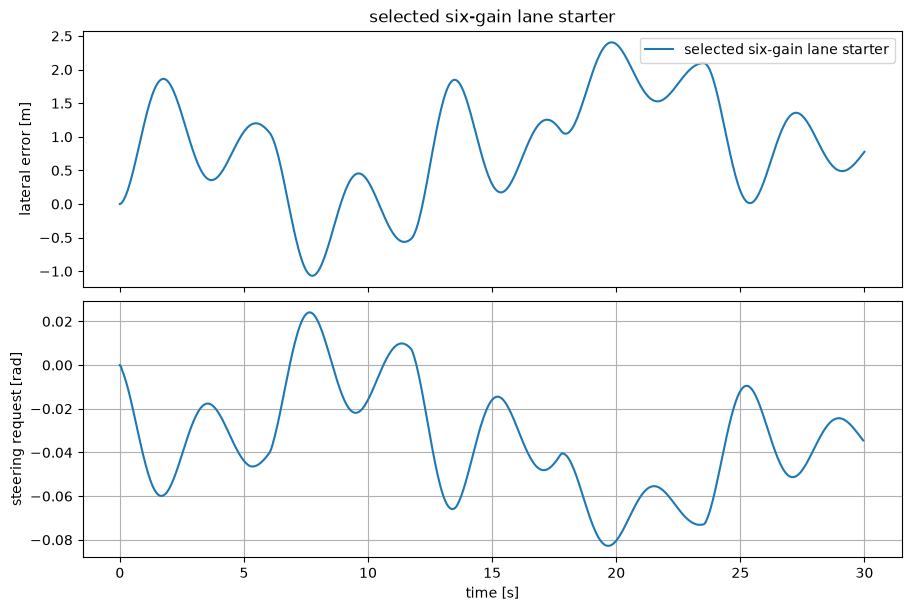

In [84]:
LANE_STARTER_TIME_SERIES, LANE_STARTER_FIGURE_PATH = run_pid_response(
    LANE_TUNING_ENVIRONMENT_KWARGS,
    SELECTED_PID_GAINS,
    "selected six-gain lane starter",
    "lane",
    "lane_starter_response.png",
)

### Your turn

Return to `pid-gains`, change only the three lateral values, and rerun from that one cell through this plot and the staged evidence. Describe the trace with the vocabulary above; do not search for an optimum.

## Lane evidence: P, then D, then I

Read the stages in order. `lateral_P` is lateral P-only evidence for response strength in the second-order teaching model. `lateral_D` adds damping. `lateral_I` restores the selected integral gain to address residual curve and steering-offset bias. Every stage is derived from the same six values in `pid-gains`.

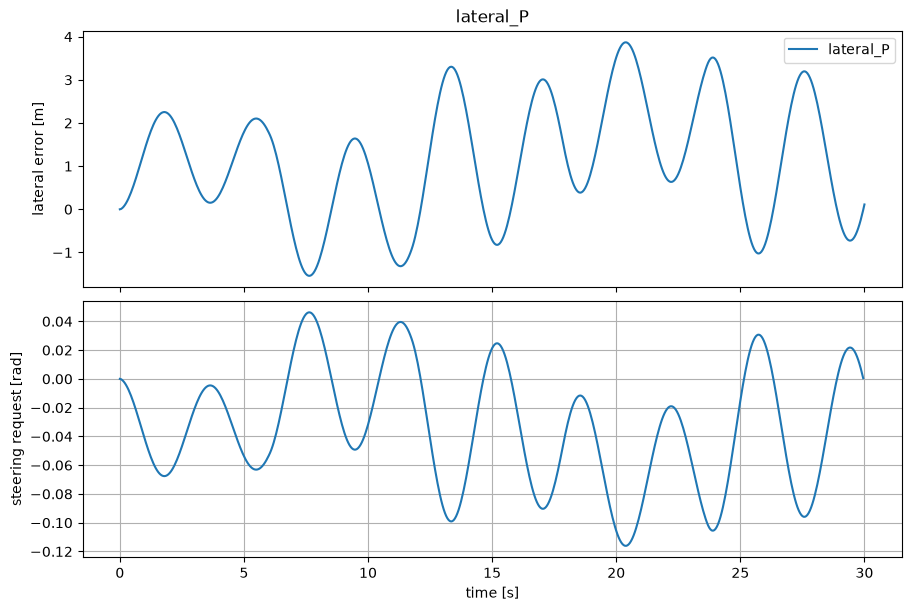

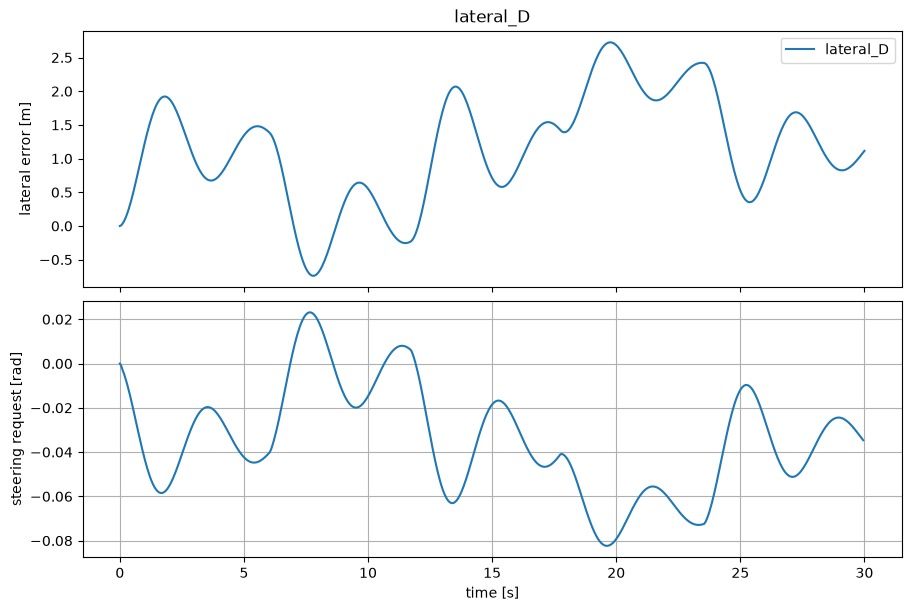

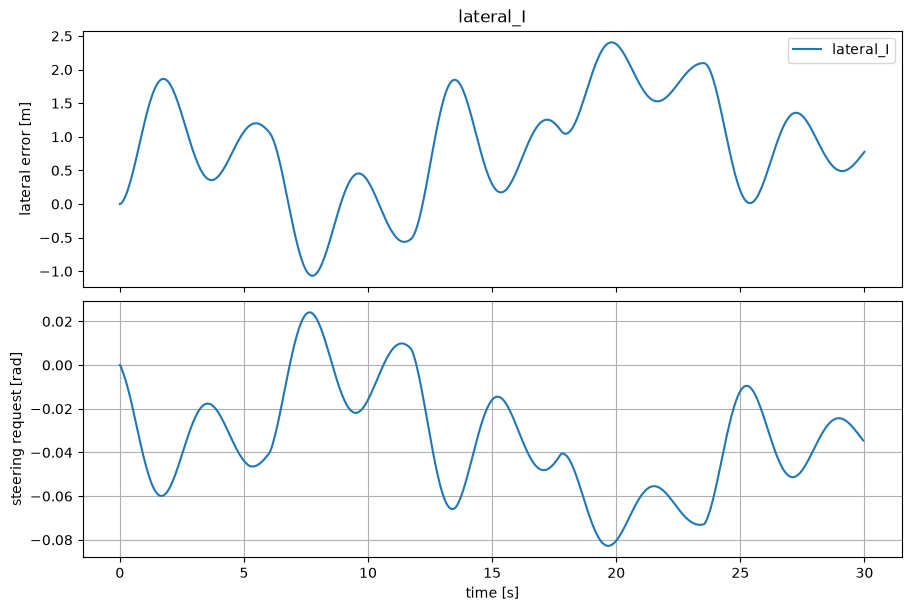

{'stage': 'lateral_P', 'mean_abs_lateral_error_m': 1.471639603312854, 'mean_abs_speed_error_mps': 0.038185211664031625, 'terminated': False, 'truncated': False}
{'stage': 'lateral_D', 'mean_abs_lateral_error_m': 1.220634925803681, 'mean_abs_speed_error_mps': 0.038185211664031625, 'terminated': False, 'truncated': False}
{'stage': 'lateral_I', 'mean_abs_lateral_error_m': 1.0016269125665163, 'mean_abs_speed_error_mps': 0.038185211664031625, 'terminated': False, 'truncated': False}


In [85]:
LANE_TUNING_RESULTS, LANE_TUNING_SUMMARY_ROWS, LANE_TUNING_FIGURE_PATHS = (
    run_tuning_stages(
        LANE_TUNING_ENVIRONMENT_KWARGS,
        LANE_TUNING_STAGE_SPECS,
        "lane",
    )
)
for row in LANE_TUNING_SUMMARY_ROWS:
    print(row)

### What you should see

Three plots appear in the order `lateral_P`, `lateral_D`, `lateral_I`. Smoke mode checks that every stage runs; in full mode, compare settling, overshoot, damping, and residual bias before deciding whether to edit the same six-gain cell.

## Variable-recommendation Road configuration

The same course [Road schema](../docs/road.md) and [environment configuration](../docs/ad_gym.md) apply. The centered 3.6-m lane and constant cross-section are declared once and inherited. This mode reuses every shared lane-environment property documented above; only the Road reference and both deterministic initial-speed bounds change to 80 km/h.

| Property | Unit | Allowed / selected value | Default / inheritance | Reason |
|---|---|---|---|---|
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].geometry.type` | unitless | `straight` | required per element | opening high-speed segment |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].geometry.length_m` | m | `200` | no inheritance | provides preview braking distance |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].speed_limit_kph` | km/h | `80` | inherited until changed | sets initial recommendation |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].cross_section_width_interpolation` | unitless | `constant` | inherited | keeps lane width fixed |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].lanes.reference_line_role` | unitless | `lane_center` | inherited | keeps reference line as target |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].lanes.reference_lane.width_m.start` | m | `3.6` | required when introduced | sets full lane width |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].lanes.reference_lane.width_m.end` | m | `3.6` | later elements inherit | keeps width constant |
| `VARIABLE_SPEED_ROAD_SPEC.elements[0].lanes.reference_lane.surface` | unitless | `tarmac` | inherited | identifies driving surface |
| `VARIABLE_SPEED_ROAD_SPEC.elements[1].geometry.type` | unitless | `circular_arc` | required per element | creates the lower recommendation |
| `VARIABLE_SPEED_ROAD_SPEC.elements[1].geometry.curvature_per_m` | 1/m | `+1/90` | no inheritance | enters the 60-km/h curvature band |
| `VARIABLE_SPEED_ROAD_SPEC.elements[1].geometry.sweep_angle_deg` | deg | `60` | no inheritance | fixes turn extent |
| `VARIABLE_SPEED_ROAD_SPEC.elements[2].geometry.type` | unitless | `straight` | required per element | follows the speed reduction |
| `VARIABLE_SPEED_ROAD_SPEC.elements[2].geometry.length_m` | m | `500` | no inheritance | keeps the rollout away from road end |
| `VARIABLE_SPEED_ROAD_SPEC.elements[2].speed_limit_kph` | km/h | `60` | explicit new value | retains the lower recommendation |
| `VARIABLE_SPEED_ENVIRONMENT_KWARGS.road_spec` | unitless | `VARIABLE_SPEED_ROAD_SPEC` mapping | replaces only the shared template Road reference | activates the 80-to-60 recommendation profile |
| `VARIABLE_SPEED_ENVIRONMENT_KWARGS.initial_state_config.bounds.body_motion.longitudinal_velocity_mps.lower` | m/s | `80/3.6` | replaces the shared 60-km/h lower bound; equals upper | starts at the initial recommendation |
| `VARIABLE_SPEED_ENVIRONMENT_KWARGS.initial_state_config.bounds.body_motion.longitudinal_velocity_mps.upper` | m/s | `80/3.6` | replaces the shared 60-km/h upper bound; equals lower | starts at the initial recommendation |
| `variable_speed_road.validate_speed_transitions.speed_sources` | unitless | selector list `["recommended_speed"]` | explicit public validation argument | validates the recommendation configuration actually followed by the policy |
| `variable_speed_road.validate_speed_transitions.deceleration_limit_mps2` | m/s^2 | positive; `4.0` | explicit public validation argument | checks the Road transition against the preview braking limit |

In [86]:
VARIABLE_SPEED_ROAD_SPEC = {
    "elements": [
        {
            "geometry": {"type": "straight", "length_m": 200.0},
            "speed_limit_kph": 80.0,
            "cross_section_width_interpolation": "constant",
            "lanes": {"reference_line_role": "lane_center", "reference_lane": {"width_m": {"start": 3.6, "end": 3.6}, "surface": "tarmac"}},
        },
        {"geometry": {"type": "circular_arc", "curvature_per_m": 1.0 / 90.0, "sweep_angle_deg": 60.0}},
        {"geometry": {"type": "straight", "length_m": 500.0}, "speed_limit_kph": 60.0},
    ]
}
variable_speed_road = Road(road_spec=VARIABLE_SPEED_ROAD_SPEC)
VARIABLE_SPEED_TRANSITION_ISSUES = variable_speed_road.validate_speed_transitions(
    speed_sources=["recommended_speed"], deceleration_limit_mps2=4.0
)
print("Recommended-speed transition validation:", VARIABLE_SPEED_TRANSITION_ISSUES)
VARIABLE_SPEED_ENVIRONMENT_KWARGS = make_local_pid_environment_kwargs(
    VARIABLE_SPEED_ROAD_SPEC, 80.0 / 3.6
)


Recommended-speed transition validation: []


## Add preview before cruise tuning

Current speed and the current recommendation cannot anticipate a reduction. The `exists`, next-value, and reference-line-distance observations activate the continuous braking envelope already implemented in the local policy. Preview is required before the variable-speed tuning runs; there is deliberately no unsafe comparator without it.

Pure PID feedback is model-free: its gains map current and past errors to commands without an explicit plant model. The governor makes the composite policy model-based because it uses mass, normalized motor-force gain, braking kinematics, and preview distance to shape the target before feedback. The force-to-command conversion is exact only for this deliberately simple linear force model; richer command maps, rolling resistance, and aerodynamic drag change realized acceleration.

In [87]:
_preview_demo_policy = SixGainPreviewPIDPolicy(
    gains=SELECTED_PID_GAINS,
    governor=PreviewGovernorConfig(
        mass_kg=COURSE_BICYCLE_MODEL_CONFIG["mass_properties"]["mass_kg"],
        normalized_motor_command_force_gain_n=COURSE_BICYCLE_MODEL_CONFIG["longitudinal_force_model"]["normalized_motor_command_force_gain_n"],
        braking_acceleration_mps2=PID_LIMITS["preview_max_deceleration_mps2"],
        time_buffer_s=PID_LIMITS["preview_time_buffer_s"],
    ),
    environment_step_duration_s=0.05,
    requested_front_wheel_angle_magnitude_limit_rad=COURSE_BICYCLE_MODEL_CONFIG["steering"]["requested_front_wheel_angle_magnitude_limit_rad"],
    lateral_integral_limit_m_s=PID_LIMITS["lateral_integral_limit_m_s"],
    longitudinal_integral_limit_m=PID_LIMITS["longitudinal_integral_limit_m"],
)
PREVIEW_DEMONSTRATION_ROWS = []
for distance_m in (200.0, 80.0, 20.0, 0.0):
    _preview_demo_policy.reset()
    _preview_demo_policy.compute_action({
        "body_longitudinal_velocity_mps": np.asarray([80.0 / 3.6], dtype=np.float32),
        "lateral_error_from_target_line_m": np.asarray([0.0], dtype=np.float32),
        "recommended_speed_mps": np.asarray([80.0 / 3.6], dtype=np.float32),
        "next_recommended_speed_change_value_mps": np.asarray([60.0 / 3.6], dtype=np.float32),
        "next_recommended_speed_change_reference_line_distance_m": np.asarray([distance_m], dtype=np.float32),
        "next_recommended_speed_change_exists": np.asarray([1.0], dtype=np.float32),
    }, {}, False, False)
    PREVIEW_DEMONSTRATION_ROWS.append({"distance_m": distance_m, "governed_speed_kph": 3.6 * _preview_demo_policy.governed_speed_history_mps[-1]})
for row in PREVIEW_DEMONSTRATION_ROWS:
    print(row)


{'distance_m': 200.0, 'governed_speed_kph': 79.99999694824218}
{'distance_m': 80.0, 'governed_speed_kph': 79.99999694824218}
{'distance_m': 20.0, 'governed_speed_kph': 70.5861158565124}
{'distance_m': 0.0, 'governed_speed_kph': 59.99999771118164}


### What you should see

The governed target stays at the current recommendation when the lower-speed point is far away, then falls continuously toward 60 km/h as the available braking distance shrinks. The rows demonstrate the supplied safe preview envelope; no unsafe comparator is run.

### What you should see

Smoke mode confirms traversal with finite measured, recommended, governed-speed, and drive traces. Full mode is where response quality is judged.

**Reminder:** use `sluggish`, `oscillatory`, `biased`, `poorly damped`, and `well-damped` in the same sense as beside the lane starter.

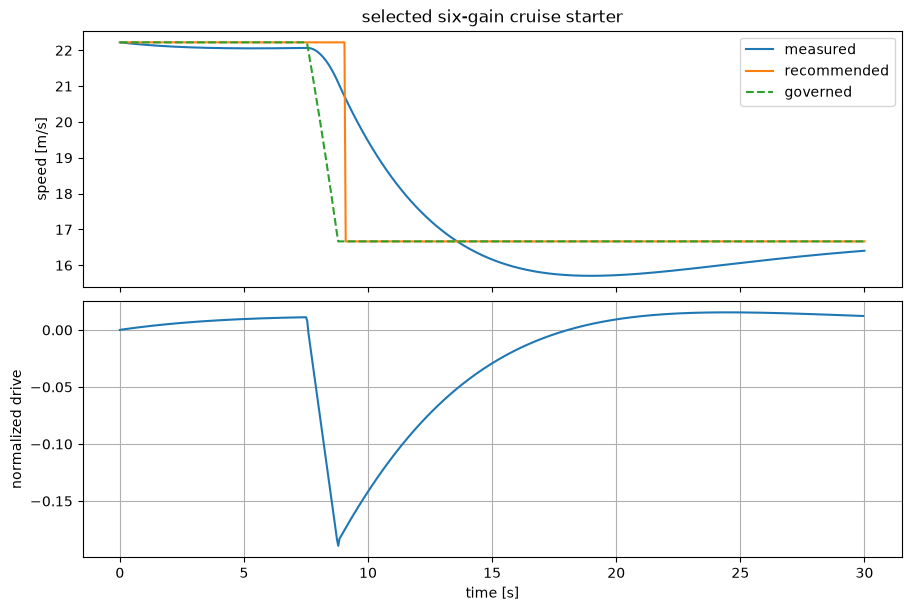

In [88]:
CRUISE_STARTER_TIME_SERIES, CRUISE_STARTER_FIGURE_PATH = run_pid_response(
    VARIABLE_SPEED_ENVIRONMENT_KWARGS,
    SELECTED_PID_GAINS,
    "selected six-gain cruise starter",
    "cruise",
    "cruise_starter_response.png",
)

### Your turn

Return to `pid-gains`, change only the three longitudinal values, and rerun from that same cell through the starter and staged evidence. Explain the trade-off you see; do not add a second gain assignment or an optimizer.

## Cruise evidence: P, then I, then D

With the selected lane gains fixed and preview already active, read `longitudinal_P` for proportional response, `longitudinal_I` for the added bias correction, and `longitudinal_D` for the optional noise-sensitive derivative contribution. This is P, then I, then D evidence derived from the same six values in `pid-gains`.

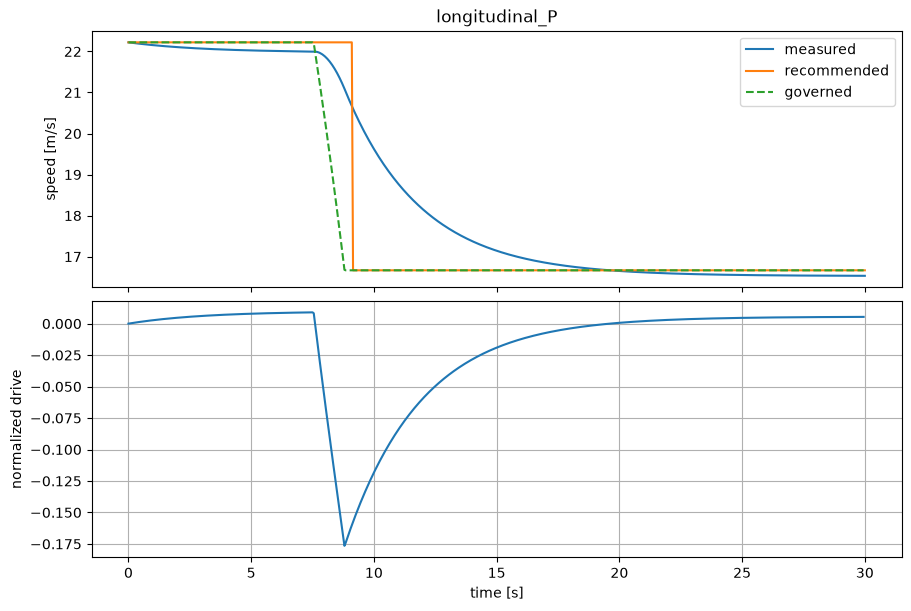

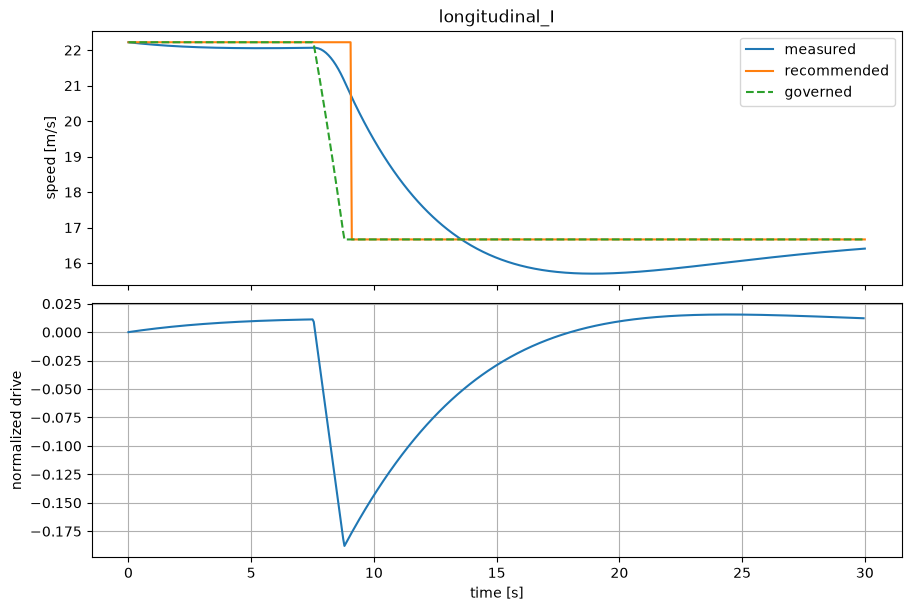

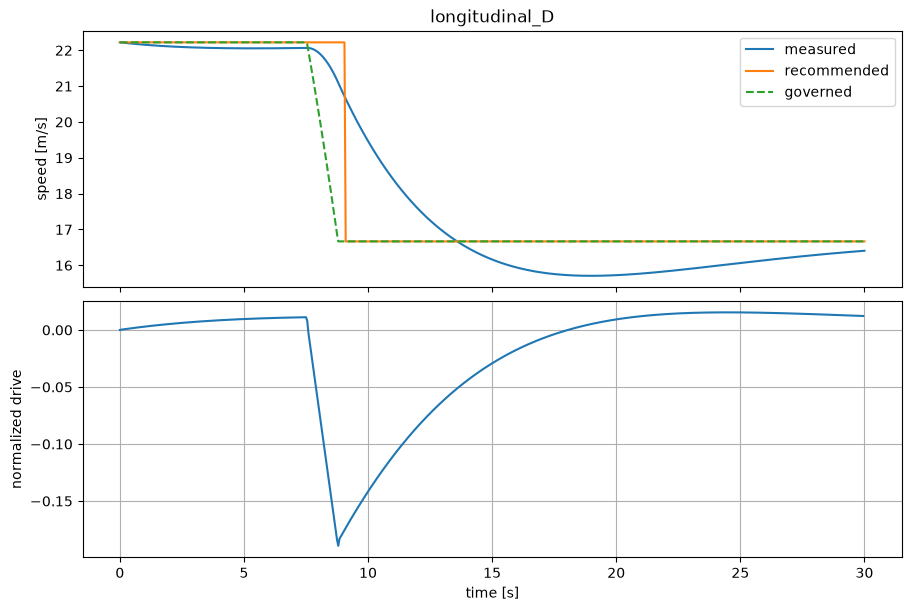

{'stage': 'longitudinal_P', 'mean_abs_lateral_error_m': 0.7860109093219364, 'mean_abs_speed_error_mps': 0.47001722529406553, 'terminated': False, 'truncated': False}
{'stage': 'longitudinal_I', 'mean_abs_lateral_error_m': 0.7853365714464975, 'mean_abs_speed_error_mps': 0.66673035232874, 'terminated': False, 'truncated': False}
{'stage': 'longitudinal_D', 'mean_abs_lateral_error_m': 0.7853542836847872, 'mean_abs_speed_error_mps': 0.6670396109785692, 'terminated': False, 'truncated': False}


In [89]:
CRUISE_TUNING_RESULTS, CRUISE_TUNING_SUMMARY_ROWS, CRUISE_TUNING_FIGURE_PATHS = (
    run_tuning_stages(
        VARIABLE_SPEED_ENVIRONMENT_KWARGS,
        CRUISE_TUNING_STAGE_SPECS,
        "cruise",
    )
)
for row in CRUISE_TUNING_SUMMARY_ROWS:
    print(row)

### What you should see

Three plots appear in the order `longitudinal_P`, `longitudinal_I`, `longitudinal_D`. Smoke mode checks that every stage runs; in full mode, compare tracking lag, steady bias, overshoot, and drive-command activity before editing the same six-gain cell.

In [90]:
BUILT_IN_METRIC_NAMES = (
    "mean_abs_lateral_error_m",
    "mean_abs_speed_error_to_recommended_kph",
)
built_in_metrics = tuple(
    metric_by_name(name) for name in BUILT_IN_METRIC_NAMES
)
LATERAL_TOLERANCE_M = 0.75


def fraction_outside_lateral_tolerance(time_series):
    lateral_error_m = np.asarray(
        time_series["lateral_error_from_target_line"],
        dtype=np.float64,
    ).reshape(-1)
    finite_lateral_error_m = lateral_error_m[np.isfinite(lateral_error_m)]
    if finite_lateral_error_m.size == 0:
        return float("nan")
    return float(
        np.mean(np.abs(finite_lateral_error_m) > LATERAL_TOLERANCE_M)
    )


fraction_outside_lateral_tolerance_metric = PerformanceMetric(
    name="fraction_outside_lateral_tolerance",
    display_name="Fraction outside lateral tolerance",
    unit="fraction",
    direction="smaller",
    requirement_group="lane_keeping",
    required_fields=("lateral_error_from_target_line",),
    equation=(
        "count(abs(finite lateral_error_from_target_line) > "
        "lateral_tolerance_m) / count(finite samples)"
    ),
    description=(
        "Fraction of finite rollout samples beyond the editable "
        "absolute lateral-error tolerance."
    ),
    justification=(
        "Separates persistent lane-margin excursions from the "
        "average-error magnitude."
    ),
    function=fraction_outside_lateral_tolerance,
    primary_aggregate="mean",
)
PID_METRICS = MetricSet(
    (*built_in_metrics, fraction_outside_lateral_tolerance_metric)
)

## Combined nominal validation

This nominal run uses the same selected six-gain object for both loops and scores its time series with the shared three-metric block. Read the metric row together with lateral error; measured, recommended, and governed speed; normalized drive; physical steering request; and cumulative reference-line progress before moving to the paired evaluation.

Shared nominal metric row: {'mean_abs_lateral_error_m': 0.7853542836847872, 'mean_abs_speed_error_to_recommended_kph': 2.4013425995228492, 'fraction_outside_lateral_tolerance': 0.5940099833610649}


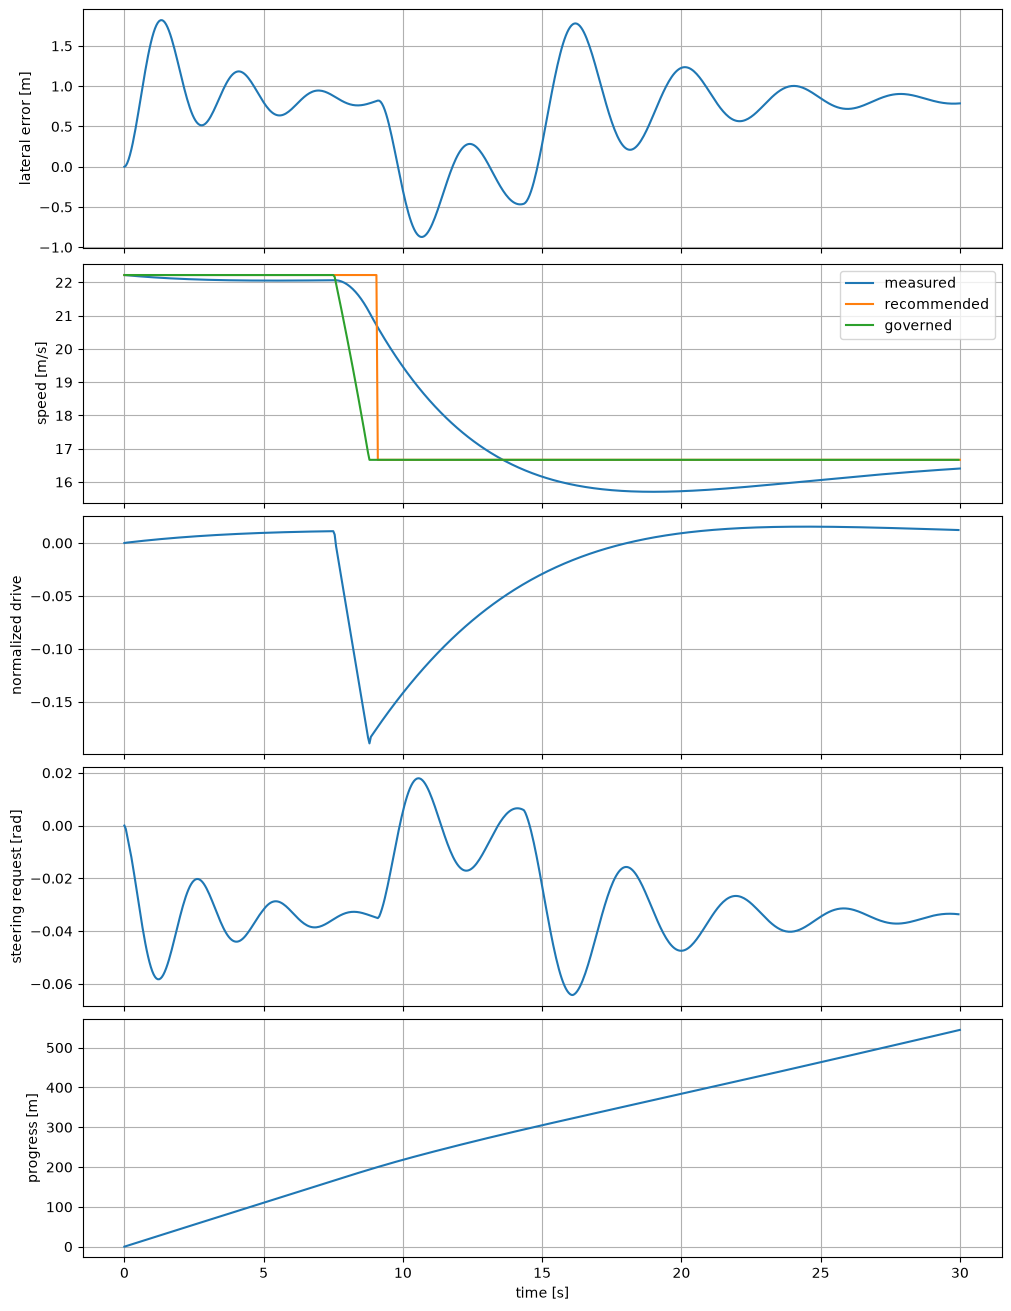

In [91]:
final_validation_environment = gymnasium.make(
    "dreamgym/autonomous_driving_env", **VARIABLE_SPEED_ENVIRONMENT_KWARGS
)
existing_figure_numbers = set(plt.get_fignums())
final_validation_figure = None
try:
    final_validation_policy = make_six_gain_preview_pid_policy(
        final_validation_environment, SELECTED_PID_GAINS
    )
    FINAL_VALIDATION_TIME_SERIES = simulate_policy(
        final_validation_environment, MODE["tuning_steps"], final_validation_policy,
        seed=TUNING_SEED, policy_seed=TUNING_SEED, reset_policy=True,
        should_save_look_ahead_results=False, should_save_observations=False, verbose=0,
    )
    FINAL_VALIDATION_TIME_SERIES = attach_governed_speed_series(
        FINAL_VALIDATION_TIME_SERIES, final_validation_policy
    )
    PID_NOMINAL_METRIC_ROW = {
        metric.name: float(metric.function(FINAL_VALIDATION_TIME_SERIES))
        for metric in PID_METRICS
    }
    print("Shared nominal metric row:", PID_NOMINAL_METRIC_ROW)
    final_validation_figure, axes = plt.subplots(
        5, 1, figsize=(10, 13), sharex=True, constrained_layout=True
    )
    time_s = np.asarray(FINAL_VALIDATION_TIME_SERIES["time_in_seconds"], dtype=float)
    axes[0].plot(time_s, FINAL_VALIDATION_TIME_SERIES["lateral_error_from_target_line"])
    axes[0].set_ylabel("lateral error [m]")
    axes[1].plot(time_s, FINAL_VALIDATION_TIME_SERIES["vx"], label="measured")
    axes[1].plot(time_s, FINAL_VALIDATION_TIME_SERIES["recommended_speed_at_closest_point"], label="recommended")
    axes[1].plot(time_s, FINAL_VALIDATION_TIME_SERIES["governed_speed_mps"], label="governed")
    axes[1].set_ylabel("speed [m/s]")
    axes[1].legend()
    axes[2].plot(time_s, FINAL_VALIDATION_TIME_SERIES["drive_command"])
    axes[2].set_ylabel("normalized drive")
    axes[3].plot(time_s, FINAL_VALIDATION_TIME_SERIES["delta_request"])
    axes[3].set_ylabel("steering request [rad]")
    axes[4].plot(time_s, FINAL_VALIDATION_TIME_SERIES["reference_line_progress_at_closest_point"])
    axes[4].set_ylabel("progress [m]")
    axes[4].set_xlabel("time [s]")
    for axis in axes:
        axis.grid(True)
    FINAL_VALIDATION_FIGURE_PATH = save_figure(
        final_validation_figure, OUTPUT_ROOT / "combined_pid_validation.png"
    )
    plt.show()
finally:
    final_validation_environment.close()
    for figure_number in set(plt.get_fignums()) - existing_figure_numbers:
        plt.close(figure_number)


### What you should see

Smoke mode confirms bounded traversal, a three-metric row, and all five finite evidence panels without judging tuning quality. In full mode, use the longer traces to assess lane and speed quality together; the later paired evaluation remains a separate activity.

## Compare the selected gains on one shared evaluation

candidate block: the 3x3 grid keeps the useful proportional gains comparison, labels the unchanged centre as `student-selected`, and adds the packaged benchmark. The benchmark is not a controlled ablation: it uses different observations, privileged ground-truth velocity, and curvature-derived speed targets.

metric block: the nominal validation, matched sweep, Pareto table, plots, and exports all reuse the same two built-ins plus the lateral-tolerance metric from the previous activity.

sweep block: mass and initial lateral position vary while the Road, observation noise, policy seeding, and rollout seeding stay fixed. Every policy receives the same ordered cases, so eligibility is checked before three-way multi-metric dominance.

Use the [performance-metric workflow](../docs/performance_metrics.md) and [policy reference](../docs/policy_classes.md) to interpret the evidence. A flagged rollout calls for inspection; the notebook leaves the final judgement to you.

In [92]:
PID_UNCERTAINTY_PARAMETERS = (
    UniformMultiplierParameter(
        name="mass_multiplier",
        path=("bicycle_model_config", "mass_properties", "mass_kg"),
        low=0.95,
        high=1.05,
    ),
    InitialStateValueParameter(
        name="initial_world_position_y_m",
        path=("world_pose", "y_m"),
        low=-0.25,
        high=0.25,
    ),
)
PID_UNCERTAINTY_SWEEP = UncertaintySweep.monte_carlo(
    PID_UNCERTAINTY_PARAMETERS,
    samples=MODE["sweep_samples"],
    seed=20260810,
)

In [93]:
GAIN_FACTORS = (0.8, 1.0, 1.2)
GAIN_VARIANTS = tuple(product(GAIN_FACTORS, GAIN_FACTORS))
PID_SELECTED_POLICY_NAME = "student-selected"


@dataclass(frozen=True)
class GainVariantMetadata:
    policy_name: str
    lateral_proportional_factor: float
    longitudinal_proportional_factor: float
    gains: PIDGains


PACKAGED_BENCHMARK_OBSERVATIONS = (
    "target_line_curvature_per_m",
    "target_line_lookahead_curvatures_per_m",
    "lateral_error_from_target_line_m",
    "ground_truth_body_longitudinal_velocity_mps",
    "ground_truth_body_lateral_velocity_mps",
)
PID_UNION_OBSERVATIONS = tuple(dict.fromkeys(
    (*LOCAL_PID_OBSERVATIONS, *PACKAGED_BENCHMARK_OBSERVATIONS)
))
PID_UNION_OBSERVATION_CONFIG = deepcopy(LOCAL_PID_OBSERVATION_CONFIG)
PID_UNION_OBSERVATION_CONFIG.update({
    "target_line_curvature_per_m": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
    "target_line_lookahead": {
        "maximum_distance_m": 60.0,
        "sample_count": 1,
        "curvatures_per_m": {
            "destination": "observation",
            "scaling_factor": 1.0,
        },
    },
    "ground_truth_body_longitudinal_velocity_mps": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
    "ground_truth_body_lateral_velocity_mps": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
})
PID_UNION_OBSERVATION_CONFIG["lateral_error_from_target_line_m"][
    "noise_standard_deviation_m"
] = 0.0
PID_UNION_OBSERVATION_CONFIG["fixed_noise_seed"] = TUNING_SEED

PID_SWEEP_ENVIRONMENT_KWARGS = deepcopy(VARIABLE_SPEED_ENVIRONMENT_KWARGS)
PID_SWEEP_ENVIRONMENT_KWARGS["bicycle_model_config"] = deepcopy(
    COURSE_BICYCLE_MODEL_CONFIG
)
PID_SWEEP_ENVIRONMENT_KWARGS["road_spec"] = VARIABLE_SPEED_ROAD_SPEC
PID_SWEEP_ENVIRONMENT_KWARGS["observation_config"] = (
    PID_UNION_OBSERVATION_CONFIG
)
PID_EVALUATION_CONFIG = AutonomousDrivingEvaluationConfig(
    n_steps=MODE["sweep_steps"],
    base_env_kwargs=PID_SWEEP_ENVIRONMENT_KWARGS,
    include_look_ahead_results=False,
    include_observations=False,
    verbose=0,
)

policy_factory_environment = gymnasium.make(
    "dreamgym/autonomous_driving_env",
    **PID_SWEEP_ENVIRONMENT_KWARGS,
)
try:
    local_policy_specs = []
    gain_metadata = {}
    for lateral_factor, longitudinal_factor in GAIN_VARIANTS:
        if (lateral_factor, longitudinal_factor) == (1.0, 1.0):
            gains = SELECTED_PID_GAINS
            policy_name = PID_SELECTED_POLICY_NAME
        else:
            gains = replace(
                SELECTED_PID_GAINS,
                lateral_proportional_gain_rad_per_m=(
                    SELECTED_PID_GAINS.lateral_proportional_gain_rad_per_m
                    * lateral_factor
                ),
                longitudinal_proportional_gain_s_per_m=(
                    SELECTED_PID_GAINS.longitudinal_proportional_gain_s_per_m
                    * longitudinal_factor
                ),
            )
            policy_name = (
                f"local_pid_lat_{lateral_factor:.1f}_long_{longitudinal_factor:.1f}"
                .replace(".", "p")
            )
        metadata = GainVariantMetadata(
            policy_name,
            lateral_factor,
            longitudinal_factor,
            gains,
        )
        gain_metadata[policy_name] = metadata
        local_policy_specs.append(PolicySpec(
            name=policy_name,
            policy=make_six_gain_preview_pid_policy(
                policy_factory_environment,
                gains,
            ),
        ))
    packaged_policy = PIDPolicyForAutonomousDriving(
        delta_request_max=policy_factory_environment.unwrapped.car.normalized_config[
            "steering"
        ]["requested_front_wheel_angle_magnitude_limit_rad"]
    )
finally:
    policy_factory_environment.close()

LOCAL_PID_POLICY_SPECS = tuple(local_policy_specs)
GAIN_VARIANT_METADATA_BY_POLICY_NAME = MappingProxyType(dict(gain_metadata))
GAIN_METADATA_BY_POLICY_NAME = MappingProxyType({
    policy_name: metadata.gains
    for policy_name, metadata
    in GAIN_VARIANT_METADATA_BY_POLICY_NAME.items()
})
del gain_metadata
PACKAGED_BENCHMARK_POLICY_SPEC = PolicySpec(
    name="packaged_proportional_benchmark",
    policy=packaged_policy,
)
PID_POLICY_SPECS = (
    *LOCAL_PID_POLICY_SPECS,
    PACKAGED_BENCHMARK_POLICY_SPEC,
)
policy_observation_fields = {
    spec.name: LOCAL_PID_OBSERVATIONS
    for spec in LOCAL_PID_POLICY_SPECS
}
policy_observation_fields[
    PACKAGED_BENCHMARK_POLICY_SPEC.name
] = PACKAGED_BENCHMARK_OBSERVATIONS
POLICY_OBSERVATION_FIELDS_BY_NAME = MappingProxyType(
    dict(policy_observation_fields)
)
del policy_observation_fields
policy_names = [spec.name for spec in PID_POLICY_SPECS]
if len(policy_names) != len(set(policy_names)):
    raise RuntimeError("PID policy names must be unique")
if any(
    not set(fields_read).issubset(PID_UNION_OBSERVATIONS)
    for fields_read in POLICY_OBSERVATION_FIELDS_BY_NAME.values()
):
    raise RuntimeError(
        "each policy observation subset must fit the union configuration"
    )
for metadata in GAIN_VARIANT_METADATA_BY_POLICY_NAME.values():
    print(metadata)

GainVariantMetadata(policy_name='local_pid_lat_0p8_long_0p8', lateral_proportional_factor=0.8, longitudinal_proportional_factor=0.8, gains=PIDGains(lateral_proportional_gain_rad_per_m=0.024, lateral_integral_gain_rad_per_m_s=0.002, lateral_derivative_gain_rad_s_per_m=0.004, longitudinal_proportional_gain_s_per_m=0.032, longitudinal_integral_gain_per_m=0.005, longitudinal_derivative_gain_s2_per_m=0.001))
GainVariantMetadata(policy_name='local_pid_lat_0p8_long_1p0', lateral_proportional_factor=0.8, longitudinal_proportional_factor=1.0, gains=PIDGains(lateral_proportional_gain_rad_per_m=0.024, lateral_integral_gain_rad_per_m_s=0.002, lateral_derivative_gain_rad_s_per_m=0.004, longitudinal_proportional_gain_s_per_m=0.04, longitudinal_integral_gain_per_m=0.005, longitudinal_derivative_gain_s2_per_m=0.001))
GainVariantMetadata(policy_name='local_pid_lat_0p8_long_1p2', lateral_proportional_factor=0.8, longitudinal_proportional_factor=1.2, gains=PIDGains(lateral_proportional_gain_rad_per_m=0.0

In [94]:
pid_evaluation_results = evaluate_policies_over_sweep(
    policies=PID_POLICY_SPECS,
    config=PID_EVALUATION_CONFIG,
    metrics=PID_METRICS,
    sweep=PID_UNCERTAINTY_SWEEP,
    include_per_rollout_metrics=True,
)


### What you should see

Each policy reports requested, contributing, and flagged rollout counts from the same cases. Eligible policies have complete unflagged evidence and finite values for all three shared metrics. A flag prompts inspection rather than an automatic tuning judgement.

In [95]:
if pid_evaluation_results.per_rollout_metric_rows is None:
    raise RuntimeError("per-rollout metrics are required for paired evaluation")
pid_metric_rows = list(pid_evaluation_results.per_rollout_metric_rows)
pid_rollout_index_rows = list(pid_evaluation_results.rollout_index_rows)
expected_policy_names = tuple(spec.name for spec in PID_POLICY_SPECS)
expected_rollout_count = int(PID_UNCERTAINTY_SWEEP.sample_count or 0)
expected_identities = {
    (policy_name, rollout_index)
    for policy_name in expected_policy_names
    for rollout_index in range(expected_rollout_count)
}
metric_identities = [
    (str(row["policy_name"]), int(row["rollout_index"]))
    for row in pid_metric_rows
]
index_identities = [
    (str(row["policy_name"]), int(row["rollout_index"]))
    for row in pid_rollout_index_rows
]
if (
    len(metric_identities) != len(set(metric_identities))
    or len(index_identities) != len(set(index_identities))
    or set(metric_identities) != expected_identities
    or set(index_identities) != expected_identities
):
    raise RuntimeError("paired results require one unique policy/rollout identity")
metric_row_by_identity = dict(zip(metric_identities, pid_metric_rows))
index_row_by_identity = dict(zip(index_identities, pid_rollout_index_rows))
if any(
    (
        bool(metric_row_by_identity[identity].get("terminated", False)),
        bool(metric_row_by_identity[identity].get("truncated", False)),
    )
    != (
        bool(index_row_by_identity[identity].get("terminated", False)),
        bool(index_row_by_identity[identity].get("truncated", False)),
    )
    for identity in expected_identities
):
    raise RuntimeError("metric and index row flag metadata must match")

parameter_names = tuple(
    parameter.name for parameter in PID_UNCERTAINTY_PARAMETERS
)
expected_samples = tuple(PID_UNCERTAINTY_SWEEP.samples())
for row in (*pid_metric_rows, *pid_rollout_index_rows):
    rollout_index = int(row["rollout_index"])
    expected_values = expected_samples[rollout_index].values
    if any(
        name not in row or row[name] != expected_values[name]
        for name in parameter_names
    ):
        raise RuntimeError("all policies must use identical sampled cases")

objective_metrics = tuple(PID_METRICS)
if (
    len(objective_metrics) < 2
    or any(
        metric.direction not in (
            MetricDirection.SMALLER,
            MetricDirection.BIGGER,
        )
        for metric in objective_metrics
    )
):
    raise RuntimeError(
        "at least two direction-eligible objectives are required"
    )
PID_PARETO_OBJECTIVE_NAMES = tuple(
    metric.name for metric in objective_metrics
)

aggregate_by_name = {
    str(row["policy_name"]): row
    for row in pid_evaluation_results.aggregate_rows
}
if (
    len(aggregate_by_name) != len(pid_evaluation_results.aggregate_rows)
    or set(aggregate_by_name) != set(expected_policy_names)
):
    raise RuntimeError("aggregate rows must match the unique policy names")
PID_SUMMARY_ROWS = []
PID_ELIGIBILITY_ROWS = []
PID_ELIGIBLE_AGGREGATE_ROWS = []
for policy_name in expected_policy_names:
    aggregate_row = aggregate_by_name[policy_name]
    rollout_count = int(aggregate_row["rollout_count"])
    metric_rollout_count = int(aggregate_row["metric_rollout_count"])
    flagged_rollout_count = int(aggregate_row["flagged_rollout_count"])
    policy_metric_rows = [
        row
        for row in pid_metric_rows
        if str(row["policy_name"]) == policy_name
    ]
    actual_flagged_count = sum(
        bool(row.get("terminated", False))
        or bool(row.get("truncated", False))
        for row in policy_metric_rows
    )
    actual_counts = (
        len(policy_metric_rows),
        len(policy_metric_rows) - actual_flagged_count,
        actual_flagged_count,
    )
    if (
        rollout_count,
        metric_rollout_count,
        flagged_rollout_count,
    ) != actual_counts:
        raise RuntimeError(
            "aggregate counts must match per-rollout flag metadata"
        )
    if rollout_count != expected_rollout_count:
        raise RuntimeError(
            "requested rollout count must match the paired sweep"
        )
    summary_row = {
        "policy_name": policy_name,
        "rollout_count": rollout_count,
        "metric_rollout_count": metric_rollout_count,
        "flagged_rollout_count": flagged_rollout_count,
        "flagged_rate": (
            flagged_rollout_count / rollout_count
            if rollout_count
            else float("nan")
        ),
    }
    summary_row.update({
        metric.name + "__primary": aggregate_row[
            metric.name + "__primary"
        ]
        for metric in PID_METRICS
    })
    PID_SUMMARY_ROWS.append(summary_row)

    reasons = []
    if flagged_rollout_count > 0:
        reasons.append("flagged rollout count is nonzero")
    if metric_rollout_count == 0:
        reasons.append("no metric-contributing rollouts")
    nonfinite_objectives = []
    for name in PID_PARETO_OBJECTIVE_NAMES:
        try:
            value = float(aggregate_row[name + "__primary"])
        except (TypeError, ValueError):
            value = float("nan")
        if not np.isfinite(value):
            nonfinite_objectives.append(name)
    if nonfinite_objectives:
        reasons.append(
            "non-finite objective primary: "
            + ", ".join(nonfinite_objectives)
        )
    eligible = not reasons
    PID_ELIGIBILITY_ROWS.append({
        "policy_name": policy_name,
        "eligible": eligible,
        "exclusion_reason": "; ".join(reasons),
    })
    if eligible:
        PID_ELIGIBLE_AGGREGATE_ROWS.append(aggregate_row)
if len(PID_ELIGIBLE_AGGREGATE_ROWS) < 2:
    raise RuntimeError(
        "at least two eligible policies are required for Pareto membership"
    )

flagged_metric_rows = [
    row
    for row in pid_metric_rows
    if bool(row.get("terminated", False))
    or bool(row.get("truncated", False))
]
concerning_pool = flagged_metric_rows if flagged_metric_rows else pid_metric_rows
if not concerning_pool:
    raise RuntimeError("at least one per-rollout metric row is required")
PID_CONCERNING_METRIC_NAME = BUILT_IN_METRIC_NAMES[0]


def concerning_sort_key(row):
    try:
        value = float(
            row.get(PID_CONCERNING_METRIC_NAME, float("nan"))
        )
    except (TypeError, ValueError):
        value = float("nan")
    finite = bool(np.isfinite(value))
    return (
        0 if finite else 1,
        -value if finite else 0.0,
        str(row["policy_name"]),
        int(row["rollout_index"]),
    )


PID_CONCERNING_METRIC_ROW = min(
    concerning_pool,
    key=concerning_sort_key,
)
PID_CONCERNING_IDENTITY = (
    str(PID_CONCERNING_METRIC_ROW["policy_name"]),
    int(PID_CONCERNING_METRIC_ROW["rollout_index"]),
)
print(
    "Aggregate objective values are conditional on contributing, "
    "unflagged rollouts."
)
print(
    "A flag is not automatically a controller failure; "
    "inspect the selected rerun."
)
for row in PID_SUMMARY_ROWS:
    print(row)
for row in PID_ELIGIBILITY_ROWS:
    print(row)

Aggregate objective values are conditional on contributing, unflagged rollouts.
A flag is not automatically a controller failure; inspect the selected rerun.
{'policy_name': 'local_pid_lat_0p8_long_0p8', 'rollout_count': 32, 'metric_rollout_count': 32, 'flagged_rollout_count': 0, 'flagged_rate': 0.0, 'mean_abs_lateral_error_m__primary': 0.9114154976331827, 'mean_abs_speed_error_to_recommended_kph__primary': 2.891047933957821, 'fraction_outside_lateral_tolerance__primary': 0.6130766832917706}
{'policy_name': 'local_pid_lat_0p8_long_1p0', 'rollout_count': 32, 'metric_rollout_count': 32, 'flagged_rollout_count': 0, 'flagged_rate': 0.0, 'mean_abs_lateral_error_m__primary': 0.9098855086100296, 'mean_abs_speed_error_to_recommended_kph__primary': 2.517066184422024, 'fraction_outside_lateral_tolerance__primary': 0.6100374064837906}
{'policy_name': 'local_pid_lat_0p8_long_1p2', 'rollout_count': 32, 'metric_rollout_count': 32, 'flagged_rollout_count': 0, 'flagged_rate': 0.0, 'mean_abs_lateral_er

### What you should see

One membership row appears for every eligible candidate, including `student-selected` when it is eligible. Front membership and direct dominance use all three shared metrics together; the table is evidence for your judgement, not a tuning verdict.

In [96]:
policy_names = [
    row["policy_name"]
    for row in PID_ELIGIBLE_AGGREGATE_ROWS
]
assert len(policy_names) == len(set(policy_names))
PID_PARETO_ROWS = compute_pareto_front(
    PID_ELIGIBLE_AGGREGATE_ROWS,
    PID_METRICS,
    metric_names=PID_PARETO_OBJECTIVE_NAMES,
)
PID_PARETO_MEMBERSHIP_ROWS = [
    {
        "policy_name": row["policy_name"],
        "pareto_status": row["pareto_status"],
        "is_pareto_front": row["is_pareto_front"],
        "dominated_by": list(row["dominated_by"]),
        "dominates": list(row["dominates"]),
    }
    for row in PID_PARETO_ROWS
]
for row in PID_PARETO_MEMBERSHIP_ROWS:
    print(row)

{'policy_name': 'local_pid_lat_0p8_long_0p8', 'pareto_status': 'dominated', 'is_pareto_front': False, 'dominated_by': ['local_pid_lat_0p8_long_1p0', 'local_pid_lat_0p8_long_1p2', 'student-selected', 'local_pid_lat_1p0_long_1p2', 'local_pid_lat_1p2_long_0p8', 'local_pid_lat_1p2_long_1p0', 'local_pid_lat_1p2_long_1p2'], 'dominates': ['packaged_proportional_benchmark']}
{'policy_name': 'local_pid_lat_0p8_long_1p0', 'pareto_status': 'dominated', 'is_pareto_front': False, 'dominated_by': ['local_pid_lat_0p8_long_1p2', 'student-selected', 'local_pid_lat_1p0_long_1p2', 'local_pid_lat_1p2_long_1p0', 'local_pid_lat_1p2_long_1p2'], 'dominates': ['local_pid_lat_0p8_long_0p8', 'packaged_proportional_benchmark']}
{'policy_name': 'local_pid_lat_0p8_long_1p2', 'pareto_status': 'dominated', 'is_pareto_front': False, 'dominated_by': ['local_pid_lat_1p2_long_1p2'], 'dominates': ['local_pid_lat_0p8_long_0p8', 'local_pid_lat_0p8_long_1p0', 'packaged_proportional_benchmark']}
{'policy_name': 'local_pid_lat

### What you should see

Three eligible-candidate bar plots appear in the shared metric order. Lower bars are better for each metric, but a single bar does not replace the three-metric Pareto comparison.

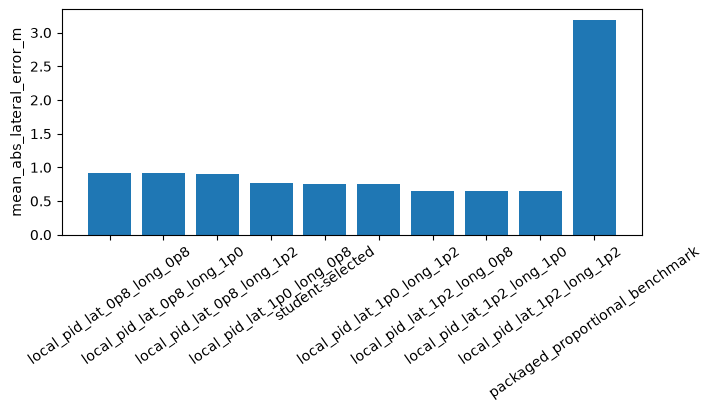

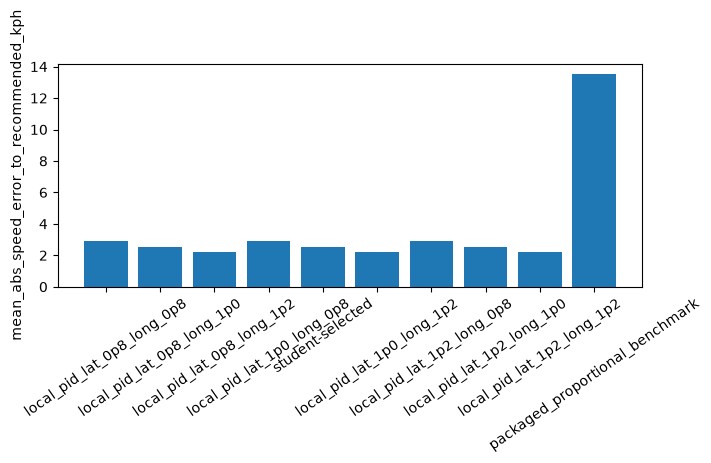

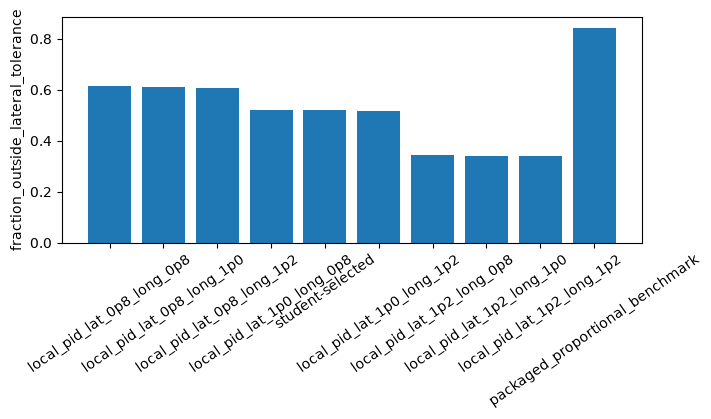

In [97]:
PID_EXPORT_DIRECTORY = OUTPUT_ROOT / "paired-gain-grid"
if not PID_EXPORT_DIRECTORY.resolve().is_relative_to(
    OUTPUT_ROOT.resolve()
):
    raise RuntimeError(
        "PID export directory must stay below OUTPUT_ROOT"
    )
PID_EXPORT_DIRECTORY.mkdir(parents=True, exist_ok=True)
objective_bar_figure_numbers_before = set(plt.get_fignums())
PID_OBJECTIVE_BAR_PATHS = {}
try:
    for metric in PID_METRICS:
        figure = plot_policy_metric_bars(
            PID_ELIGIBLE_AGGREGATE_ROWS,
            metric.name,
        )
        PID_OBJECTIVE_BAR_PATHS[metric.name] = save_figure(
            figure,
            PID_EXPORT_DIRECTORY
            / (metric.name + "_eligible_bar.png"),
        )
        plt.show()
finally:
    for figure_number in (
        set(plt.get_fignums())
        - objective_bar_figure_numbers_before
    ):
        plt.close(figure_number)

### What you should see

The retained policy/rollout identity is rerun on its exact mass and initial-position sample. Inspect the trajectory and time-series plots to distinguish an evaluator flag from a controller-quality concern.

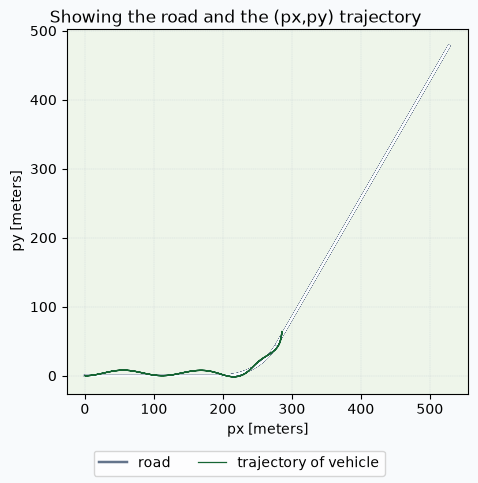

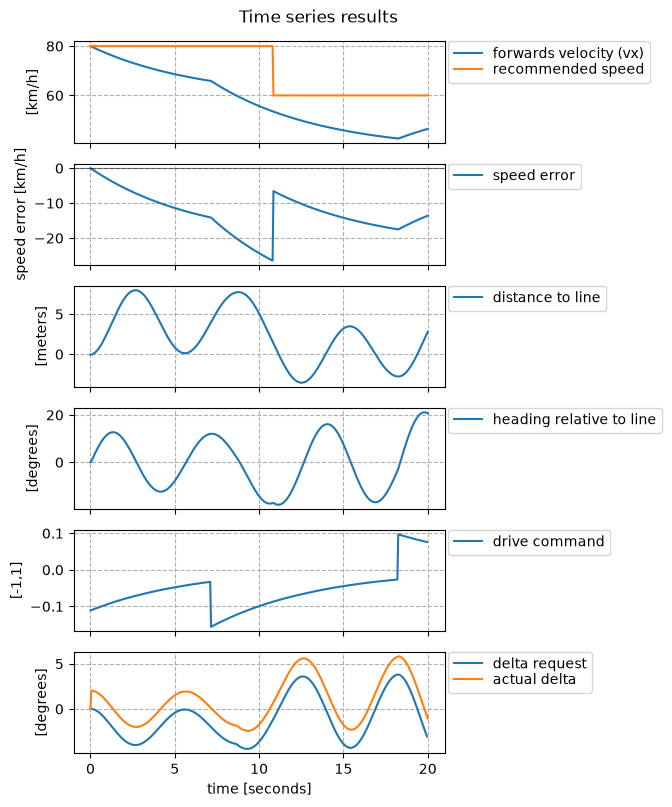

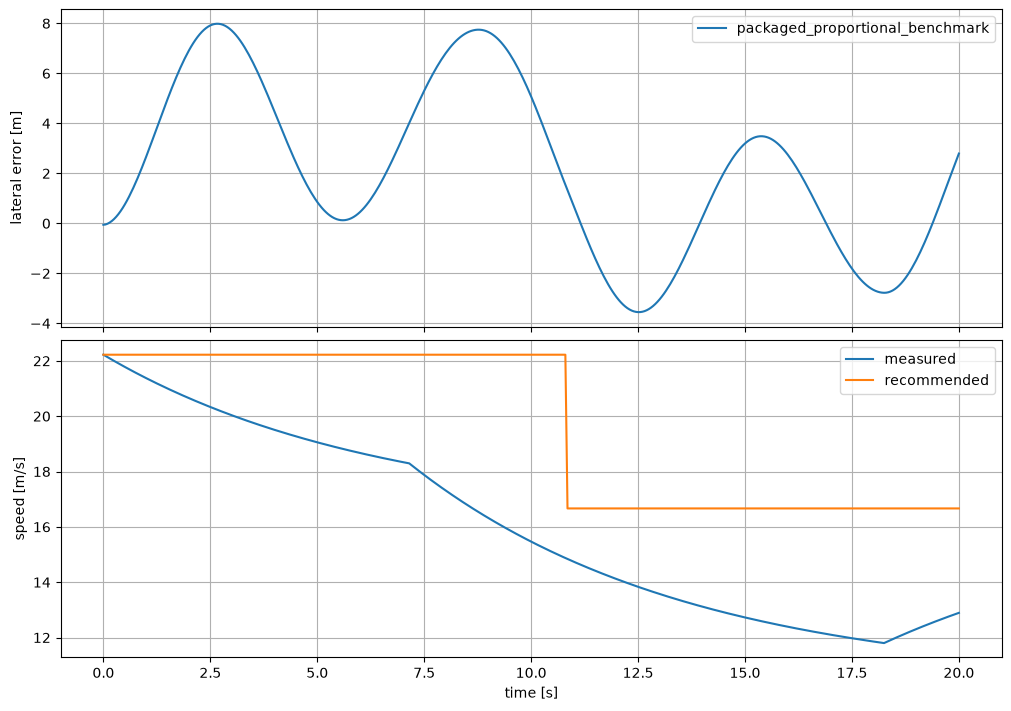

In [98]:
if not PID_EXPORT_DIRECTORY.resolve().is_relative_to(
    OUTPUT_ROOT.resolve()
):
    raise RuntimeError(
        "PID export directory must stay below OUTPUT_ROOT"
    )
matching_policy_specs = [
    spec
    for spec in PID_POLICY_SPECS
    if spec.name == PID_CONCERNING_IDENTITY[0]
]
matching_rollout_index_rows = [
    row
    for row in pid_rollout_index_rows
    if (
        str(row["policy_name"]),
        int(row["rollout_index"]),
    )
    == PID_CONCERNING_IDENTITY
]
if (
    len(matching_policy_specs) != 1
    or len(matching_rollout_index_rows) != 1
):
    raise RuntimeError(
        "concerning identity must resolve to one policy and index row"
    )
PID_CONCERNING_POLICY_SPEC = matching_policy_specs[0]
PID_CONCERNING_ROLLOUT_INDEX_ROW = matching_rollout_index_rows[0]
PID_CONCERNING_TIME_SERIES = rerun_sweep_rollout(
    PID_CONCERNING_POLICY_SPEC,
    PID_EVALUATION_CONFIG,
    PID_UNCERTAINTY_SWEEP,
    PID_CONCERNING_ROLLOUT_INDEX_ROW,
)

concerning_rollout_index = PID_CONCERNING_IDENTITY[1]
matching_samples = [
    sample
    for rollout_index, sample
    in enumerate(PID_UNCERTAINTY_SWEEP.samples())
    if rollout_index == concerning_rollout_index
]
if len(matching_samples) != 1:
    raise RuntimeError(
        "concerning rollout index must resolve to one sweep sample"
    )
concerning_sample = matching_samples[0]
if any(
    PID_CONCERNING_ROLLOUT_INDEX_ROW[parameter.name]
    != concerning_sample.values[parameter.name]
    for parameter in PID_UNCERTAINTY_PARAMETERS
):
    raise RuntimeError(
        "concerning rollout metadata must match its sweep sample"
    )
concerning_environment_kwargs, concerning_post_create = (
    concerning_sample.apply_to_env_kwargs(
        PID_SWEEP_ENVIRONMENT_KWARGS
    )
)
if concerning_post_create:
    raise RuntimeError(
        "the fixed-control PID sweep must not require post-create changes"
    )
concerning_environment = gymnasium.make(
    "dreamgym/autonomous_driving_env",
    **concerning_environment_kwargs,
)
concerning_figure_numbers_before = set(plt.get_fignums())
PID_CONCERNING_FIGURE_PATHS = {}
try:
    figures = plot_simulation_results(
        concerning_environment,
        PID_CONCERNING_TIME_SERIES,
        should_plot_reward=False,
        should_plot_speed_error=True,
    )
    for figure_name, figure in figures.items():
        PID_CONCERNING_FIGURE_PATHS[figure_name] = save_figure(
            figure,
            PID_EXPORT_DIRECTORY
            / ("concerning_" + figure_name + ".png"),
        )

    overlay_figure, overlay_axes = plt.subplots(
        2,
        1,
        figsize=(10, 7),
        sharex=True,
        constrained_layout=True,
    )
    time_s = np.asarray(
        PID_CONCERNING_TIME_SERIES["time_in_seconds"],
        dtype=float,
    )
    overlay_axes[0].plot(
        time_s,
        PID_CONCERNING_TIME_SERIES[
            "lateral_error_from_target_line"
        ],
        label=PID_CONCERNING_POLICY_SPEC.name,
    )
    overlay_axes[0].set_ylabel("lateral error [m]")
    overlay_axes[1].plot(
        time_s,
        PID_CONCERNING_TIME_SERIES["vx"],
        label="measured",
    )
    overlay_axes[1].plot(
        time_s,
        PID_CONCERNING_TIME_SERIES[
            "recommended_speed_at_closest_point"
        ],
        label="recommended",
    )
    overlay_axes[1].set_ylabel("speed [m/s]")
    overlay_axes[1].set_xlabel("time [s]")
    for axis in overlay_axes:
        axis.grid(True)
        axis.legend()
    PID_CONCERNING_FIGURE_PATHS[
        "time_series_overlay"
    ] = save_figure(
        overlay_figure,
        PID_EXPORT_DIRECTORY
        / "concerning_time_series_overlay.png",
    )
    plt.show()
finally:
    concerning_environment.close()
    for figure_number in (
        set(plt.get_fignums())
        - concerning_figure_numbers_before
    ):
        plt.close(figure_number)

In [99]:
if not PID_EXPORT_DIRECTORY.resolve().is_relative_to(
    OUTPUT_ROOT.resolve()
):
    raise RuntimeError(
        "PID export directory must stay below OUTPUT_ROOT"
    )
PID_EXPORT_DIRECTORY.mkdir(parents=True, exist_ok=True)
PID_EXPECTED_METRIC_TABLE_KEYS = {
    "aggregate_csv",
    "rollout_index_csv",
    "per_rollout_csv",
    "aggregate_markdown",
    "aggregate_latex",
}
PID_METRIC_TABLE_PATHS = save_metric_tables(
    pid_evaluation_results,
    PID_EXPORT_DIRECTORY,
    file_prefix="pid_gain_grid",
    metrics=PID_METRICS,
)
if set(PID_METRIC_TABLE_PATHS) != PID_EXPECTED_METRIC_TABLE_KEYS:
    raise RuntimeError(
        "paired PID metric table export set is incomplete"
    )

metric_plot_figure_numbers_before = set(plt.get_fignums())
try:
    PID_METRIC_PLOT_VIEW = replace(
        pid_evaluation_results,
        per_rollout_metric_rows=None,
    )
    PID_METRIC_PLOT_PATHS = save_performance_metric_plots(
        PID_METRIC_PLOT_VIEW,
        PID_EXPORT_DIRECTORY,
        metric_names=PID_METRICS.names(),
    )
finally:
    for figure_number in (
        set(plt.get_fignums())
        - metric_plot_figure_numbers_before
    ):
        plt.close(figure_number)
expected_metric_plot_keys = {
    name + "_bar"
    for name in PID_METRICS.names()
}
if set(PID_METRIC_PLOT_PATHS) != expected_metric_plot_keys:
    raise RuntimeError(
        "paired PID metric plot export set is incomplete"
    )


def json_compatible(value):
    if isinstance(value, dict):
        return {
            str(key): json_compatible(item)
            for key, item in value.items()
        }
    if isinstance(value, (list, tuple)):
        return [json_compatible(item) for item in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


PID_SUMMARY_EXPORT_PATH = (
    PID_EXPORT_DIRECTORY / "pid_gain_grid_summary.json"
)
PID_SUMMARY_EXPORT_PATH.write_text(
    json.dumps(
        json_compatible({
            "gain_metadata": [
                {
                    "policy_name": record.policy_name,
                    "lateral_proportional_factor": (
                        record.lateral_proportional_factor
                    ),
                    "longitudinal_proportional_factor": (
                        record.longitudinal_proportional_factor
                    ),
                    "gains": {
                        field.name: getattr(
                            record.gains,
                            field.name,
                        )
                        for field in fields(record.gains)
                    },
                }
                for record
                in GAIN_VARIANT_METADATA_BY_POLICY_NAME.values()
            ],
            "summary_rows": PID_SUMMARY_ROWS,
            "eligibility_rows": PID_ELIGIBILITY_ROWS,
            "pareto_membership_rows": (
                PID_PARETO_MEMBERSHIP_ROWS
            ),
        }),
        indent=2,
        sort_keys=True,
        allow_nan=False,
    ),
    encoding="utf-8",
)
exported_paths = (
    *PID_METRIC_TABLE_PATHS.values(),
    *PID_METRIC_PLOT_PATHS.values(),
    *PID_OBJECTIVE_BAR_PATHS.values(),
    *PID_CONCERNING_FIGURE_PATHS.values(),
    PID_SUMMARY_EXPORT_PATH,
)
if not all(
    Path(path).resolve().is_relative_to(OUTPUT_ROOT.resolve())
    for path in exported_paths
):
    raise RuntimeError(
        "PID artifacts must stay below OUTPUT_ROOT"
    )
print(PID_METRIC_TABLE_PATHS)
print(PID_METRIC_PLOT_PATHS)
print(PID_PARETO_MEMBERSHIP_ROWS)

{'aggregate_csv': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/pid_gain_grid_aggregate.csv'), 'rollout_index_csv': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/pid_gain_grid_rollout_index.csv'), 'aggregate_markdown': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/pid_gain_grid_aggregate.md'), 'aggregate_latex': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/pid_gain_grid_aggregate.tex'), 'per_rollout_csv': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/pid_gain_grid_per_rollout.csv')}
{'mean_abs_lateral_error_m_bar': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/mean_abs_lateral_error_m_bar.png'), 'mean_abs_speed_error_to_recommended_kph_bar': PosixPath('notebook_outputs/pid-synthesis-and-tuning/paired-gain-grid/mean_abs_speed_error_to_recommended_kph_bar.png'), 'fraction_outside_lateral_tolerance_bar': PosixPath('notebook_outputs/pid-synthesis-